<a href="https://colab.research.google.com/github/jose-esquivel-dev/Analitica_de_Datos/blob/main/U3/Practica_3/AD_U3_Practica3_LLanasMia.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Datos Alumno**

# * **Nombre**: Mia Llanas Hernández
# * **No control**: 22111513

#### **En esta actividad trabajarás con datos históricos del precio de mercado de la acción de alguna de las grandes compañías como Nvidia, Tesla, Google.**

Sigue los siguientes pasos para descargar los datos del problema:

    Ir a la página de Yahoo!-Finance: https://finance.yahoo.com/

En el buscador de dicha página pon las iniciales de la compañía deseada. Deberás seleccionar alguna de las siguientes compañías: AAPL, NVDA, TSLA, GOOG, AMZN o MSFT.

Seleccionar la pestaña "Historical Data".

Pulsa "Download" para descargar el archivo de datos históricos de los movimientos diarios de los últimos 5 años.



# **En esta Actividad se trabajará con los datos historicos del precio de mercado de la acción, Compañia TESLA.**

# **0 - Preparando los datos ORIGINALES**

In [1]:
# Omitamos los Warnings por el momento:
import warnings
warnings.filterwarnings("ignore")

In [2]:
#!pip freeze   # Si deseas verificar qué librerías y versiones ya tiene google-Colab preinstaladas,
               # en particular "prophet" que usaremos en este ejercicio.

In [3]:

#Libreria para obtener el conjunto de datos
import yfinance as yf

#Para manipular datos
import numpy as np
import pandas as pd

#Para graficar
import matplotlib.pyplot as plt

#Error cuadratico medio
from sklearn.metrics import mean_squared_error
import math

#Para aplicar escalamiento de datos [0,1]
from sklearn.preprocessing import MinMaxScaler

from prophet import Prophet
from statsmodels.graphics.tsaplots import month_plot, quarter_plot
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf   # gráficos de autocorrelación

#A) **Descargar el archivo de datos históricos de los movimientos diarios de los últimos 5 años.**

In [4]:
#Escribimos las iniciales de la compañia con la que deseemos trabajar. En esta ocasión trabajare con Tesla

ticker_symbol = 'MSFT'                           # selecciona las iniciales de la compañía deseada.
data = yf.download(ticker_symbol, period='5y')   # Se indica el período de 5 años y descargamos.
data.to_csv('historical_data.csv')               # Guardamos los datos


[*********************100%***********************]  1 of 1 completed


In [5]:
data.head() #muestra los primeros 5 registros

Price,Close,High,Low,Open,Volume
Ticker,MSFT,MSFT,MSFT,MSFT,MSFT
Date,,,,,
2021-11-24,324.268402,324.508309,320.429884,322.704201,21661300
2021-11-26,316.370605,324.287548,314.873586,320.852088,24217200
2021-11-29,323.040070,325.343174,321.226356,321.418293,28563500
2021-11-30,317.243835,324.143572,315.708423,321.782892,42885600
2021-12-01,316.754364,325.582964,316.092247,321.600509,33337600


In [6]:
#convierte a dataframe
path = 'historical_data.csv'
df = pd.read_csv(path, header=2)   #header=2 para que no tome en cuenta los 2 primeros renglones, ya que estan vacios
df.columns=['Date','Close','High','Low','Open','Volume'] #Se agrega columna Date
df.head()

,Date,Close,High,Low,Open,Volume
0,2021-11-24,324.268402,324.508309,320.429884,322.704201,21661300
1,2021-11-26,316.370605,324.287548,314.873586,320.852088,24217200
2,2021-11-29,323.040070,325.343174,321.226356,321.418293,28563500
3,2021-11-30,317.243835,324.143572,315.708423,321.782892,42885600
4,2021-12-01,316.754364,325.582964,316.092247,321.600509,33337600


In [7]:
df.info()   # Verifica detalles del conjunto de datos a utilizar
            # El dataframe cuenta con 1258 registros
            # 7 columnas las cuales son: Date, Adj close, Close, High, Low, Open, Volume
            # Variable Date, tipo Object -> se cambiará a tipo Fecha

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1254 entries, 0 to 1253
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    1254 non-null   object 
 1   Close   1254 non-null   float64
 2   High    1254 non-null   float64
 3   Low     1254 non-null   float64
 4   Open    1254 non-null   float64
 5   Volume  1254 non-null   int64  
dtypes: float64(4), int64(1), object(1)
memory usage: 58.9+ KB


#**B)Utiliza solamente los datos de la columna "Adj Close" en esta actividad.**

In [8]:
# Renombremos de manera estándar las columnas de fechas y valores de la
# serie de tiempo, donde además la fecha la trasnformamos a tipo datetime:

df = df.drop(columns=['High','Low','Open','Volume']) #Elimina columnas que no se requieren
df = df.rename(columns={'Close':'y'})                    #Columna Adj Close, renombramos por y
df['Date'] = pd.to_datetime(df['Date'])                      #Convertimos variable Date de tipo Object a Datetime
df.head()                                                    #Muestra primeros 5 registros para visualizar el cambio

,Date,y
0,2021-11-24,324.268402
1,2021-11-26,316.370605
2,2021-11-29,323.040070
3,2021-11-30,317.243835
4,2021-12-01,316.754364


In [9]:
df.info() #Creación de un nuevo df, el cual consta de 2 columnas, las cuales son:
          #Variable Date -> de tipo datetime64, nos ayuda a representar un rango de fechas muy amplio con presición nanosegundos
          #Variable 'Adj Close' -> fue renombrada por 'y' de tipo flotante,

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1254 entries, 0 to 1253
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    1254 non-null   datetime64[ns]
 1   y       1254 non-null   float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 19.7 KB


En particular datetime64[ns] nos ayuda a representar un rango de fechas muy amplio con precisión de nanosegundos.

### **Agreguemos los ajustes usuales en Series de tiempo:**

In [10]:
# Hagamos una copia del DataFrame df con índices temporales:

df_temp = df.copy()                     #Genera copia del df originar en nueva variable temporal de nombre: df_temp
df_temp.set_index('Date', inplace=True) #se establece como indice Variable Date,
                                        #parametro inplace=True, es para guardar los cambios
df_temp.head()                          #visualizar los cambios

,y
Date,
2021-11-24,324.268402
2021-11-26,316.370605
2021-11-29,323.040070
2021-11-30,317.243835
2021-12-01,316.754364


In [11]:
#Muestra información sobre numero total de registros y columnas como estan conformados el df original (df) y el df temporal (df_temp)

print("DataFrame Original:\n ")
print(df.shape)      #Conformado por 1258 registros y 2 columnas (Date, y)

print("\nDataFrame Temporal:\n")
print(df_temp.shape) #Conformado por 1258 regsitros y 1 columna (y), Variable Date pase a ser indice

DataFrame Original:
 
(1254, 2)

DataFrame Temporal:

(1254, 1)


https://pandas.pydata.org/docs/reference/api/pandas.DatetimeIndex.html

In [12]:
# Ajustemos la frecuencia de los índices, para que el modelo tenga información del período en que
# se encuentran los datos:

df_temp.index =df_temp.index.tz_localize(None) #Para quitar zona horaria
df_temp.index


DatetimeIndex(['2021-11-24', '2021-11-26', '2021-11-29', '2021-11-30',
               '2021-12-01', '2021-12-02', '2021-12-03', '2021-12-06',
               '2021-12-07', '2021-12-08',
               ...
               '2026-11-10', '2026-11-11', '2026-11-12', '2026-11-13',
               '2026-11-16', '2026-11-17', '2026-11-18', '2026-11-19',
               '2026-11-20', '2026-11-23'],
              dtype='datetime64[ns]', name='Date', length=1254, freq=None)

-----------------------------------------------------------------------------
**Se puede observar que la ejecución se esta línea de código indica 'freq=None', por lo cual tendremos que definir un tipo de frecuencia (ya sea por dias, meses, años). La cual se definirá en el siguiente segmento de código que se muestra a continuación:**

-----------------------------------------------------------------------------

Para las opciones de "freq" ver la tabla que viene en esta liga:

https://pandas.pydata.org/pandas-docs/stable/user_guide/timeseries.html#offset-aliases

In [13]:
# Especifiquemos entonces que nuestros datos están registrados con una frecuencia mensual
# al inicio del mes (cada día 01 de cada mes):

df_temp = df_temp.resample('B').asfreq()#Define frecuencia B -> frecuencia del día de actividad
df_temp.index

DatetimeIndex(['2021-11-24', '2021-11-25', '2021-11-26', '2021-11-29',
               '2021-11-30', '2021-12-01', '2021-12-02', '2021-12-03',
               '2021-12-06', '2021-12-07',
               ...
               '2026-11-10', '2026-11-11', '2026-11-12', '2026-11-13',
               '2026-11-16', '2026-11-17', '2026-11-18', '2026-11-19',
               '2026-11-20', '2026-11-23'],
              dtype='datetime64[ns]', name='Date', length=1304, freq='B')

#**C)Investiga el significado de esta columna Adj-Close e inclúyelo en tu reporte del Jupyter-Notebook.**

###Investigación

-------------------------------------------------------------------------
¿Qué es el Cierre Ajustado?

Adj Close es una columna Clave dentro de los datos historicos . El **Precio Ajustado de cierre**, se apoya de dividendos y splist de acciones, que afectan el precio de la acción.

Es una versión ajustada del Precio de Cierre de una acción, después de los ajustes para todas las distribuciones de splits y dividendos aplicables, los cuales se definen a continuación:

 * **Dividendos**, Aqui es cuando la empresa distribuye dividendos a sus accionistas. El dividendo se "resta" del precio de la acción para representar el valor real de la acción después del pago realizado.

* **Splits(Divisiones de Acciones)**, Aqui es cuando el precio de la acción se ajusta para reflejar la nueva cantiad de acciones en circulación. Aumenta el número de acciones de circulación, pero la capitalización no cambia

##Importancia del Adj Close

El Adj Close, es muy importante ya que gracias a el se puede visualizar de mejor la manera la evolución del valor de la acción que se ha tenido a lo largo del tiempo. Siendo muy útil al momenteo de realizar análisis de rendimiento y asi lograr obtener una visipon más clara de cómo se ha comportado una acción dentro del mercado por un periodo de tiempo

De igual manera también es muy útil para realizar cálculos más precisos, si se desea cálcular el rendimiento total de una acción o retornos de una inversión en un cierto periodo, ya que por otro lado si se hace uso unicamente de "close" sin el ajuste, puede existir sesgo en el análisis.

--------------------------------------------------------------------

#**D)Divide los datos en Train y Test, donde Test serán los últimos 20 precios de mercado de la compañía que seleccionaste**

In [14]:
df_temp=df_temp.ffill() #para rellenar datos faltantes NaN
datos_nan=df_temp[df_temp.isna().any(axis=1)] #para verificar existencia datos faltantes
#print(datos_nan)

In [15]:
# Particionemos en entrenamiento y prueba como DataFrames de Pandas:
train = df_temp.iloc[0:-20,:] # Selecciona todos los registros, excepto últimos 20
test = df_temp.iloc[-20:,:]   # Seleccionamos los datos del últimoS 20 registros para predicción de Test.

In [16]:
test.head()  #muestra registros del test

,y
Date,
2026-10-27,530.305603
2026-10-28,529.986206
2026-10-29,529.117859
2026-10-30,520.903687
2026-11-02,506.142242


In [17]:
datos_nan=train[train.isna().any(axis=1)]
print(datos_nan) #verificamos que no existan datos faltantes NaN en Entrenamiento (train)

datos_nan=test[test.isna().any(axis=1)]
print(datos_nan) #verificamos que no exista datos faltantes NaN en Pueba (test)

Empty DataFrame
Columns: [y]
Index: []
Empty DataFrame
Columns: [y]
Index: []


In [18]:
train.shape #Entrenamiento conformado por 1285 registros y 1 columna

(1284, 1)

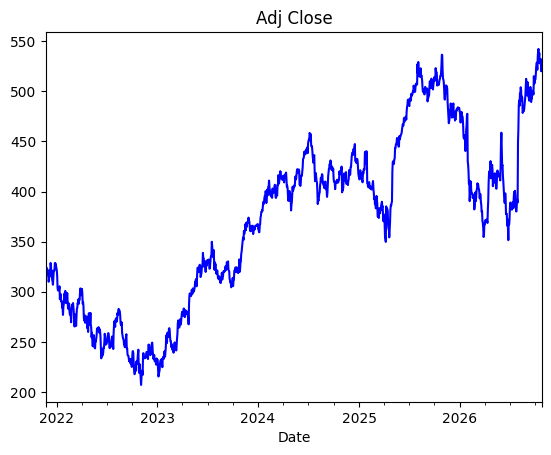

In [19]:
# Gráfico con la periodicidad anual:
train['y'].plot(title='Adj Close', style='-b')
plt.show()

## <font color=orange>**Escriba su Interpretación de la gráfica**</font>





## <font color=orange>**De este gráfico podemos observar:**

1.    Empieza de forma desendiente pero toma a forma asendiente

2.    Casi llega al maximo de la gráfica

3. Los datos suben y bajan en todas las fechas.

4. Cada dos años baja un poco

5. Cada año sube  



# **1 - Modelo ingenuo (Baseline / Persistance / Naive model)**

# **DATOS ORIGINALES**

*   El modelo ingenuo simplemente **hace la predicción del siguiente período, repitiendo el valor del último período**.

*   Este modelo se utiliza en general como punto de partida **para comparar todos los demás**.

*   Utilicemos el error RMSE (Raíz del Error Cuadrático Medio) como medida del desempeño de nuestros modelos a obtener.

In [20]:
test['y'].values #muestra valores del conjunto test en arreglo

array([530.30560303, 529.98620605, 529.11785889, 520.90368652,
       506.14224243, 519.98553467, 554.72839355, 534.89672852,
       529.5869751 , 544.12884521, 532.13201904, 520.12524414,
       521.99163818, 522.86993408, 516.99127197, 505.26394653,
       507.30999756, 498.29998779, 484.51998901, 492.5       ])

In [21]:
history = [x for x in train['y'].values]   # Definimos "history" donde de manera incremental se irán agregando registros mensuales.
predictions = list()    # Lista que contendrá las predicciones del modelo ingenuo.

for i in range(len(test['y'])):
  # Obtenemos las predicciones:
  yhat = history[-1]   # La primera vez, tomamos el último dato del Train, en las siguientes, se van agregando los datos de Test.
  predictions.append(yhat)

  # Observaciones-registros reales:
  obs = test.iloc[i]['y']   # Ahora vamos tomando los datos de Test.
  history.append(obs)  # Vamos agregando a "history" (que ya tiene todo los de Train) en cada iteración, un dato más de los de Test.
  print('>Esperado-real = %3d, Predicción = %.3f' % (obs, yhat))


# Calculamos la raíz del error cuadrático medio (RMSE):
rmse = np.sqrt(mean_squared_error(test['y'].values, predictions))
print('\nError-Modelo-Naive: RMSE: %.3f' % rmse)

>Esperado-real = 530, Predicción = 531.573
>Esperado-real = 529, Predicción = 530.306
>Esperado-real = 529, Predicción = 529.986
>Esperado-real = 520, Predicción = 529.118
>Esperado-real = 506, Predicción = 520.904
>Esperado-real = 519, Predicción = 506.142
>Esperado-real = 554, Predicción = 519.986
>Esperado-real = 534, Predicción = 554.728
>Esperado-real = 529, Predicción = 534.897
>Esperado-real = 544, Predicción = 529.587
>Esperado-real = 532, Predicción = 544.129
>Esperado-real = 520, Predicción = 532.132
>Esperado-real = 521, Predicción = 520.125
>Esperado-real = 522, Predicción = 521.992
>Esperado-real = 516, Predicción = 522.870
>Esperado-real = 505, Predicción = 516.991
>Esperado-real = 507, Predicción = 505.264
>Esperado-real = 498, Predicción = 507.310
>Esperado-real = 484, Predicción = 498.300
>Esperado-real = 492, Predicción = 484.520

Error-Modelo-Naive: RMSE: 12.496


----------------------------------------------------------------------------
## <font color=orange>**Entre el real y la predicción cambian 1 o 2 pero también cambia de 10 oh incluso 20, la predicción no es tan buena ya que hay valores acercandose al real pero también hay valores que se alejan mucho**



-----------------------------------------------------------------------------

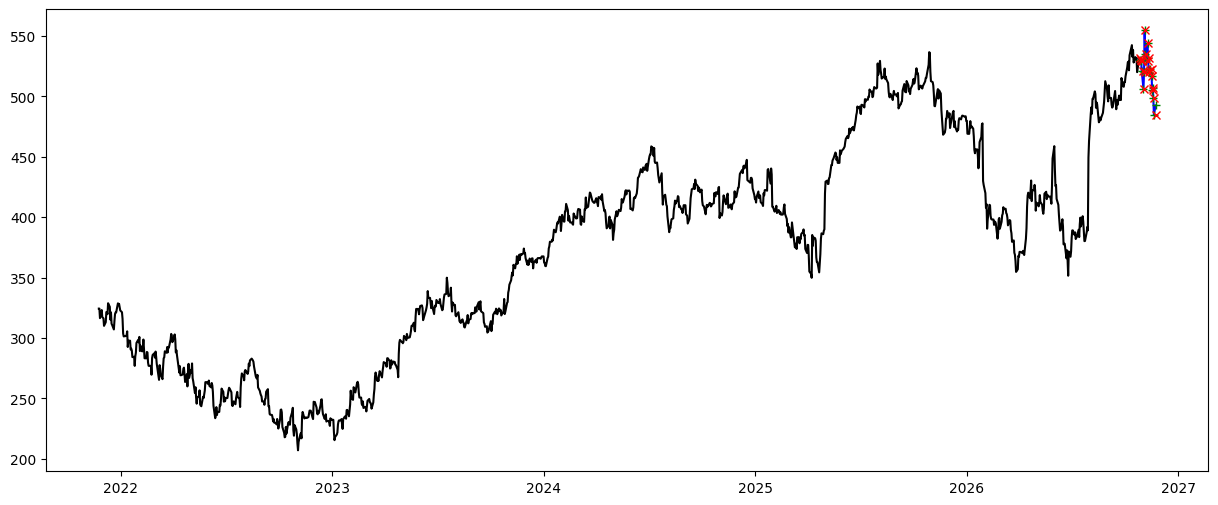

In [22]:
# Grafiquemos los resultados:

fig, ax = plt.subplots(figsize=(15, 6))
ax = plt.plot(train['y'], '-k')   # Datos de entrenamiento (los históricos).
ax = plt.plot(test['y'], '-b')    # Datos de prueba reales (los últimos 20 registros a predecir).
ax = plt.plot(test['y'],'+g')
ax = plt.plot(test.index, predictions, 'xr')  # Predicciones del modelo ingenuo.

#Verdes son los datos reales
#rojos son las predicciones

### <font color=orange>**Interpretación Gráfica.**

----------------------------------------------------------------------------
Ente los datos reales y las predicciones se puede ver que los reales son muy centrados y pocos y las predicciones estan subiendo y bajando mucho entre el valor 500 y 550 pero de ahi no pasan

----------------------------------------------------------------------------

# **2 - Modelo ARIMA**

# **DATOS ORIGINALES**

### **Análisis preliminar para obtener información de la serie de tiempo y construir el modelo ARIMA(p,d,q).**

*   **AR (AutoRegresivo):** El modelo se basa en la **relación entre un valor actual y sus valores pasados.**

*   **I (Integrado):** Se refiere a la diferenciación de la serie para hacerla estacionaria, es decir, eliminar tendencias y patrones cíclicos.

*   **MA (Media Móvil):** Usa el error de los valores pasados (las desviaciones entre valores predichos y observados) para corregir el valor actual.

##### **Ahora veamos el gráfico de descomposición de la serie de tiempo en sus componentes de tendencia (trend), estacionalidad (stationality) y residual (residual).**

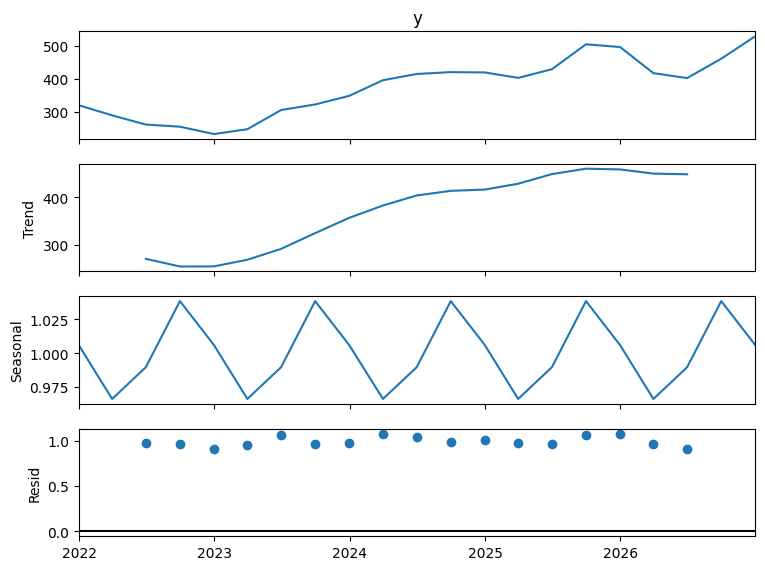

In [23]:
# Gráficos de descomposición estacional:
#parametro Q indica año
decomposition = seasonal_decompose(train['y'].resample('Q').mean(), model='multiplicative')  # <<<---- Observa que el modelo es multiplicativo
fig = decomposition.plot()
fig.set_size_inches(8,6)
plt.show()

# <font color=orange>**Interpretación de cada una de las Gráficas**

-----------------------------------------------------------------------------

En esta gráfica nos desgloza 4 gráficas:

1. **Gráfica Original**,

2. **Tendencia (Trend)**,

3. **Estacional (Seasonal)**,

4. **Residuos (Resid)**,

-----------------------------------------------------------------------------

##### **Veamos ahora estos dos gráficos que nos hablan si tenemos algún tipo de estacionalidad (i.e., periodicidad). En particular, mensual o trimestral:**

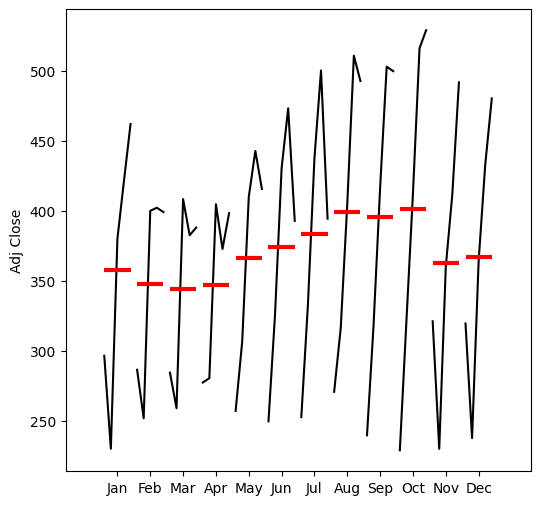

In [24]:
# Gráfica para detección de estacionalidad mensual:
fig = month_plot(train['y'].resample('M').mean(), ylabel='Adj Close')
fig.set_size_inches(6,6)
plt.show()

# <font color=orange>**Interpretación Gráfica**

-----------------------------------------------------------------------------
Aqui podemos observar que el mes de Octubre fue el que obtuvo mas ganancias ya que es el que esta por encima de los demás meses y el mes que tuvo menos ganancias es Marzo



----------------------------------------------------------------------------

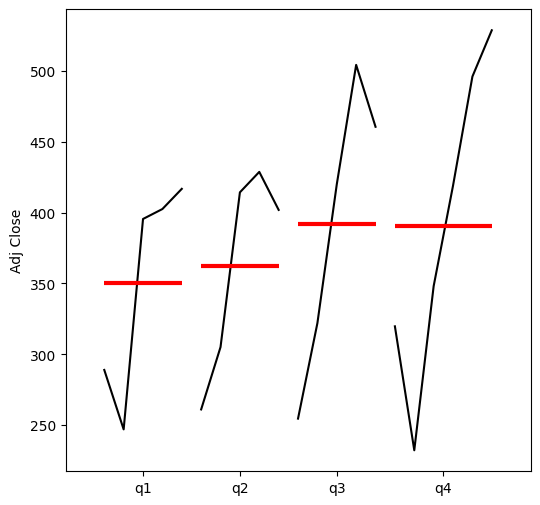

In [25]:
# Si queremos graficar y detectar estacionalidad trimestral:
fig = quarter_plot(train['y'].resample('Q').mean(), ylabel='Adj Close')
fig.set_size_inches(6,6)
plt.show()

# <font color=orange>**Interpretación Gráfica**

----------------------------------------------------------------------------
Anteriormente se interperto que el mes que mas obtuvo ganancia fue Octubre y aquí se puede observar que el tercer trimestre fue el que mas alto salio porque dentro de este se encuentra octubre y el que menos ganancia obtuvo fue el primer trimestre porque dentro de este se encuentra Marzo que fue el mes mas bajo.



----------------------------------------------------------------------------

### **Gráficos de Autocorrelación (ACF) y Autocorrelación Parcial (PACF)**

*   Los gráficos de Autocorrelación miden la correlación entre la serie de tiempo y una versión rezagada de sí misma.

*   Este tipo de correlaciones de una serie de tiempo consigo misma son llamadas "autocorrelaciones" o "correlaciones seriales".

*   En el eje horizontal se muestra el valor del desfazamiento (lag) y en el eje vertical el valor de correlación de la serie desfazada y la original.

*   El cono sombreado indica intervalos de confianza de la correlación, con un 95% de confianza de manera predeterminada.

*   Que existan autocorrelaciones significativas en estos gráficos nos habla de que la serie de tiempo no es aleatoria.

*   En estos dos gráficos (llamados en inglés "pollipop plots") hay que determinar cuántos de estos lollipops están afuera del intervalo de confianza (sin contar el inicial) antes de que entre el siguiente a la zona celeste?

*   **Gráfico ACF:** Muestra la correlación total entre la serie y sus retardos, incluyendo efectos directos e indirectos.

*   **Gráfico PACF:** Muestra la correlación directa entre la serie y sus retardos, eliminando los efectos de los retardos intermedios.

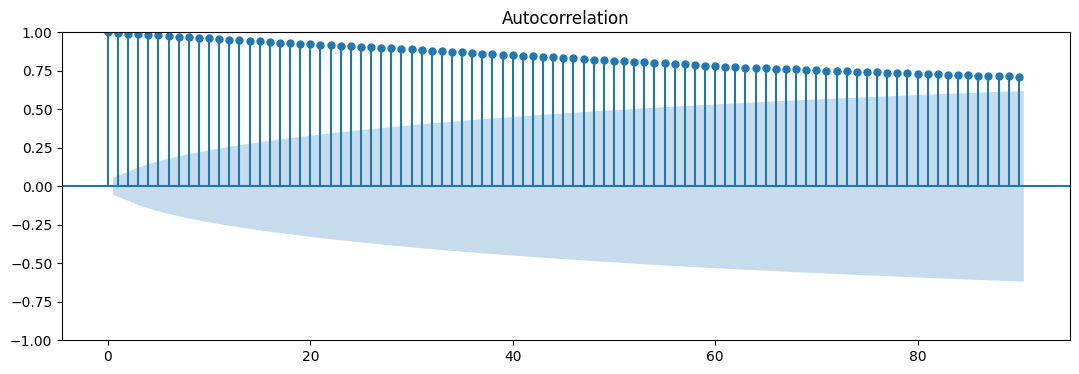

In [26]:
# Gráfico de Autocorrelación (ACF: Auto-Correlation-Function)
train['y'] = train['y'].ffill() ##Rellenan campos que estan NaN
fig,ax = plt.subplots(figsize = (13,4))
plot_acf(train['y'], lags=90, ax=ax)   # Eliges el número de unidades (meses) desfasadas. El número de "lags" es el número
plt.show()

# <font color=orange>**Intepretación Gráfica Autocorrelación (ACF)**

-----------------------------------------------------------------------------
Muestra una confienza que aumenta conforme se va aumentando mientras el modelo va mostrando su maximo de valor real.



-----------------------------------------------------------------------------

El gráfico inicia con desfase (lag) de 0, lo cual es la correlación de la serie de tiempo consigo misma, la cual es 1.

Posteriormente se muestran las correlaciones de la serie de tiempo original, con la serie desfasada "q" lugares hacia atrás, es decir, de orden "q" en la componente MA de ARIMA(p,d,q).

**El gráfico ACF nos dice en primera instancia que la componente MA de ARIMA(p,d,q) tiene un grado "q" de 13 (en la práctica se puede buscar de 0 a 13).**

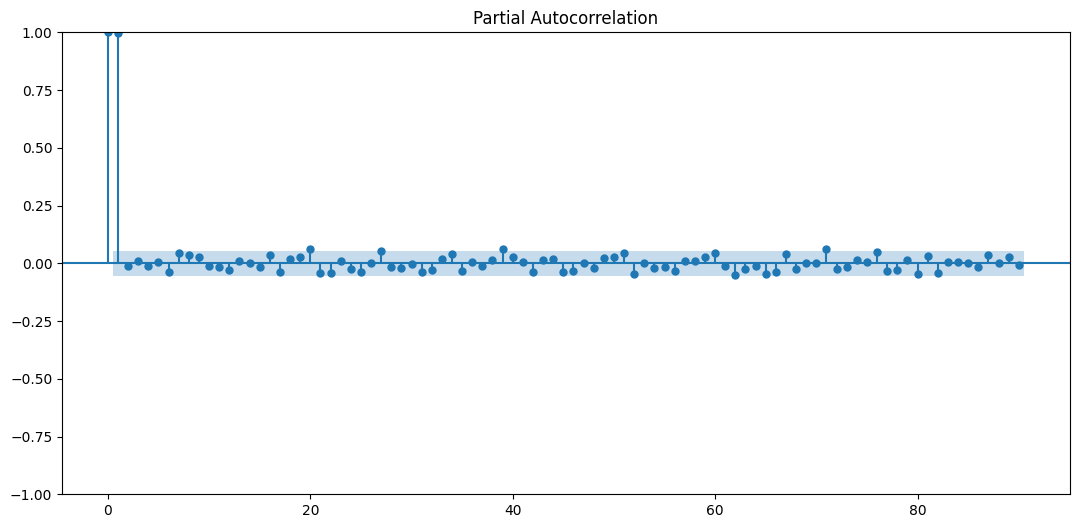

In [27]:
# Gráfico de Autocorrelación Parcial (PACF):
fig, ax = plt.subplots(figsize = (13,6))
plot_pacf(train['y'], lags = 90, ax = ax, method="ols")   # ols: regression of time series on lags of it an on constant. predetrminado method="ywm"
plt.show()

# <font color=orange>**Interpretación Gráfica Partial Autoccorelation (PACF)**

----------------------------------------------------------------------------
No sobrepasan los valores entre 0.25 y -0.25 pero al inicio se pone en uun máximo de 1.00 en el valor 0 lo cual es un retardo.


----------------------------------------------------------------------------

* PACF también inicia con la correlación de la serie de tiempo consigo misma, por ello el valor de 1.

*   **De este gráfico podemos observar que la componente AR de ARIMA(p,d,q) tiene grado p=3 o tal vez 5 (en la práctica se puede probar de 0 a 5.)**

##### Existe un buen número de librerías para el caso de pronósticos con los modelos ARIMA-SARIMA. Usaremos en este ejercicio la de Statsmodels, cuya documentación encuentras en la siguiente liga:

https://www.statsmodels.org/stable/generated/statsmodels.tsa.arima.model.ARIMA.html

In [28]:
from statsmodels.tsa.arima.model import ARIMA

In [29]:
# Lo primero es para quitar la estacionalidad y transformar un problema
# de tipo no-estacionario (SARIMA) en uno estacionario (ARIMA):

# Diferencia de datos consecutivos en el tiempo
# y podemos ahora usar ARIMA:
def difference(dataset, interval=1):
  diff = list()

  for i in range(interval, len(dataset)):
    value = dataset[i] - dataset[i - interval]
    diff.append(value)

  return np.array(diff)



# Invierte las diferencias anteriores, es decir, nos regresa la estacionalidad:
def inverse_difference(history, yhat, interval=1):
  return yhat + history[-interval]


In [30]:
# Definamos la siguiente lista de registros de pasajeros en el tiempo:
history = [x for x in train.loc[:,'y'].values]   # train-ndarray : columna solo con los registros de pasajeros "y".
                               # history-list : lista con los datos del train.

predictions = list()   # Para incluir las predicciones que vaya generando el modelo.

for i in range(len(test['y'])):
  #
  months_in_year = 12
  diff = difference(history, months_in_year)    # diff-list: lista de los datos de diferencias para transformar SARIMA en ARIMA.

  # Generamos el modelo.    (p,d,q)  p->valor definido en gráfica partial autocorrelation  d->Estacionaria  q->valor definido en grafica autocorrelacion
  model = ARIMA(diff, order=(1,0,13),) # Si aplicamos diff, entonces d=0 es aplicable.
  model_fit = model.fit(method_kwargs={'maxiter':300})  # Aumentar las iteraciones para evitar el WarningConvergence.

  yhat = model_fit.forecast()[0]   # prediccions (yhat) de cada registro, es un solo número flotante.
  yhat = inverse_difference(history, yhat, months_in_year)    # El "history" sigue siendo la lista de arriba.
                                                              # El nuevo "yhat" es cada un nuevo valor (float) de predicción.
  predictions.append(yhat)  # predictions-list : lista que se va incrementando al ir agregando cada predicción nueva.

  # Observaciones-reales:
  obs = test.iloc[i]['y']   #  cada dato es un flotante.
  history.append(obs)   #  history-list : se va incrementado a partir del Train con los registros-observaciones reales.

  print('>Esperado-real = %3d, Predicción = %.3f' % (obs, yhat))

# Error RMSE:
rmse = np.sqrt(mean_squared_error(test['y'].values, predictions))
print('\nError-Modelo-ARIMA: RMSE: %.3f' % rmse)

>Esperado-real = 530, Predicción = 531.267
>Esperado-real = 529, Predicción = 531.380
>Esperado-real = 529, Predicción = 530.940
>Esperado-real = 520, Predicción = 527.989
>Esperado-real = 506, Predicción = 519.636
>Esperado-real = 519, Predicción = 507.151
>Esperado-real = 554, Predicción = 521.209
>Esperado-real = 534, Predicción = 554.991
>Esperado-real = 529, Predicción = 533.368
>Esperado-real = 544, Predicción = 531.506
>Esperado-real = 532, Predicción = 545.722
>Esperado-real = 520, Predicción = 530.852
>Esperado-real = 521, Predicción = 519.471


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


>Esperado-real = 522, Predicción = 523.276


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


>Esperado-real = 516, Predicción = 523.800
>Esperado-real = 505, Predicción = 516.239


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


>Esperado-real = 507, Predicción = 503.502
>Esperado-real = 498, Predicción = 509.341


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


>Esperado-real = 484, Predicción = 500.580
>Esperado-real = 492, Predicción = 483.198

Error-Modelo-ARIMA: RMSE: 12.366


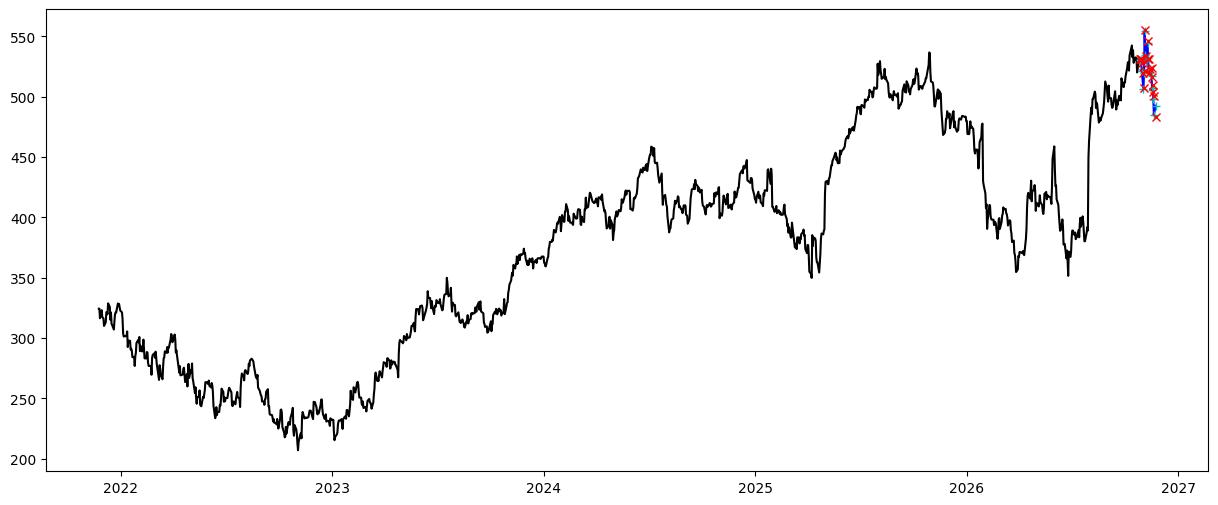

In [31]:
# Veamos su gráfico de ARIMA:
fig, ax = plt.subplots(figsize=(15, 6))
ax = plt.plot(train['y'], '-k')
ax = plt.plot(test['y'], '-b')
ax = plt.plot(test['y'], '+c')
ax = plt.plot(test.index, predictions, 'xr')

# <font color=orange>**Interpretación Gráfica ARIMA**

-----------------------------------------------------------------------------
Es una gráfica que va de forma ascendente y entre su valor real no pasa de 500 y 550 mientras que las predicciones solamente van aumentando y disminuyendo entre los valores ya mencionados.



----------------------------------------------------------------------------



# **3 - Modelo Facebook-Meta-Prophet**

# **DATOS ORIGINALES**

#### **En la liga del modelo Facebook-Prophet puedes encontrar mucho más información, además de la documentación correspondiente:**

https://facebook.github.io/prophet/

In [32]:
df_temp.head() #verificar que el df_temp este en formato correcto

,y
Date,
2021-11-24,324.268402
2021-11-25,324.268402
2021-11-26,316.370605
2021-11-29,323.040070
2021-11-30,317.243835


In [33]:
# Prophet requiere que la entrada sean dos columnas, llamadas "ds" y "y".
# Les dmos esta forma usando el DataFrame "df" inicial:
df_temp = df_temp.reset_index() #reseta el indice
df_temp = df_temp.rename(columns={'Date': 'ds'}) #renombra columna 'Date' como 'ds'
df_temp.head()


,ds,y
0,2021-11-24,324.268402
1,2021-11-25,324.268402
2,2021-11-26,316.370605
3,2021-11-29,323.040070
4,2021-11-30,317.243835


In [34]:
train =df_temp.iloc[0:-20,:] #particion Entrenamiento, todo el conjunto excepto últimos 20
test = df_temp.iloc[-20:,:]  #particion Prueba, solo ultimos 20 registros de df_temp

In [35]:
# Aplicamos el modelo Facebbok-Prophet a nuestros datos:

model = Prophet(seasonality_mode='multiplicative', #se especifica el modo multiplicativo que se definio en los modelos anteriores
                yearly_seasonality=True,       #periodo anual Verdadero
                changepoint_prior_scale=10.,   # Controla la flexibilidad de la componente Trend, mayor valor mayores fluctuaciones.
                seasonality_prior_scale=30)    # Controla la estacionalidad, mayor el valor, mayor flexibilidad en la estacionalidad.
model.fit(train)

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


In [36]:
# Calculamos el error RMSE:

pred_FP = model.predict(test)['yhat']
rmse = np.sqrt(mean_squared_error(test['y'], pred_FP))
print('\nError-Modelo-FacebookProphet: RMSE: %.3f' % rmse)


Error-Modelo-FacebookProphet: RMSE: 22.054


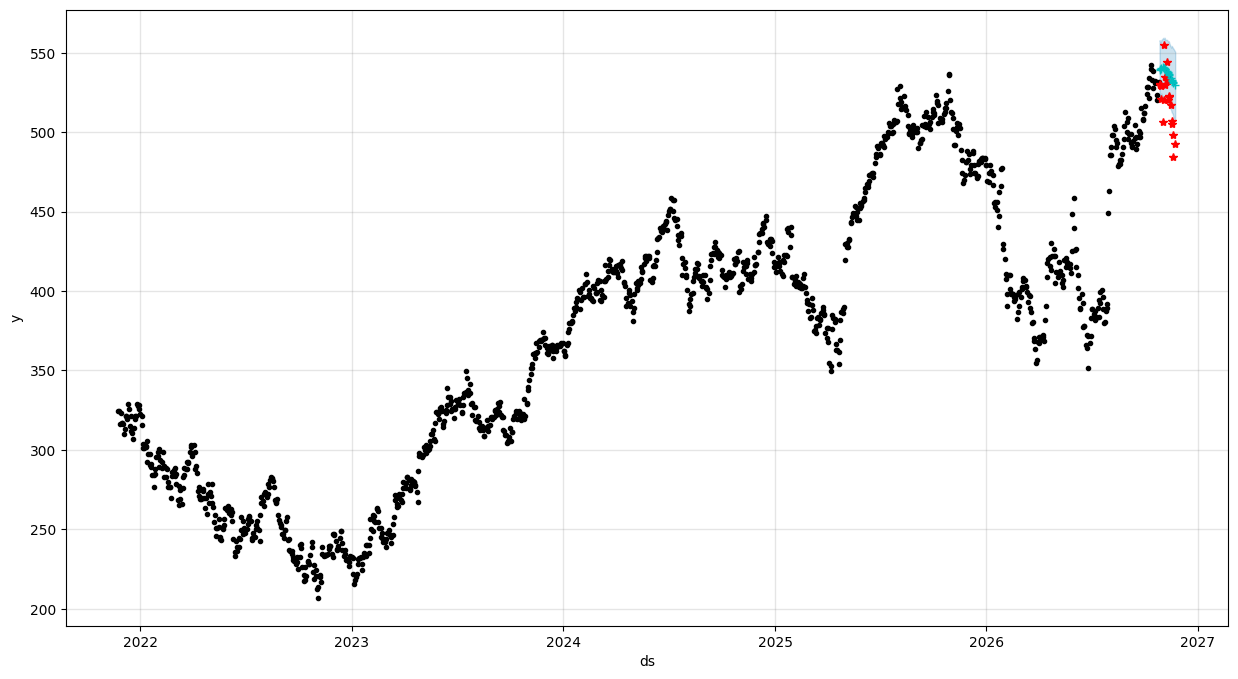

In [37]:
# La librería misma nos permite obtener las predicciones con las cotas mínima
# y máxima, además de su gráfica, como se muestra a continuación:

forecast = model.predict(test)

fig, ax = plt.subplots(figsize=(15, 8))
model.plot(forecast, ax=ax)               # Las predicciones se muestran con la línea continua, junto con su región de variabilidad de la predicción.
ax = plt.plot(test['ds'], test['y'], '*r')   # Agregamos los datos de prueba (Test) con puntos rojos, para observar la diferencia.
ax = plt.plot(test['ds'], forecast['yhat'], '+c')    # Valores reales.

#color rojo representan las predicciones
#color azul datos reales


# <font color=orange>**Interpretación Gráfica Facebook-Meta-Prophet**

-----------------------------------------------------------------------------

Puntos Rojos -> predicciones
Puntos azules -> Datos reales
parte sombreada -> intervalo de confianza de los datos



-----------------------------------------------------------------------------


# **4 - Long Short Term Memory (LSTM)**

# **DATOS ORIGINALES**

In [38]:
import tensorflow as tf

In [39]:
test.head()

,ds,y
1284,2026-10-27,530.305603
1285,2026-10-28,529.986206
1286,2026-10-29,529.117859
1287,2026-10-30,520.903687
1288,2026-11-02,506.142242


In [40]:
def preparando_datos(myData, myDate):

  # ++++++++ TRAIN +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

  # Los datos de entrenamiento son previos a la fecha "Date" que indiques y
  # tomarán hisotriales en este caso de 12 períodos previos.
  Train_Data = myData['y'][myData['ds'] < myDate].to_numpy()

  periodo = 12   # 12 meses al año

  Data_Train = []
  Data_Train_X = []
  Data_Train_Y = []

  for i in range(0, len(Train_Data), periodo):    # observa que va formando el Train set con historiales de 12 períodos consecutivos.
    try:
      Data_Train.append(Train_Data[i : i + periodo])
    except:
      pass


  # En ocasiones hay datos perdidos, en cuyo caso la última serie
  # de datos la eliminamos:
  if len(Data_Train[-1]) < periodo:
    Data_Train.pop(-1)


  # Hay que darle la forma (dimensionalidad) que requieren los modelos
  # de aprendizaje profundo, en particular la librería de TensorFlow:
  #     (batch_size, sequence_length, input_dimension).

  Data_Train_X = Data_Train[0 : -1]
  Data_Train_X = np.array(Data_Train_X)
  Data_Train_X = Data_Train_X.reshape((-1, periodo, 1))

  Data_Train_Y = Data_Train[1 : len(Data_Train)]
  Data_Train_Y = np.array(Data_Train_Y)
  Data_Train_Y = Data_Train_Y.reshape((-1, periodo, 1))


  # +++++++++++ TEST +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

  # Los datos de prueba (Test) son posteriores a la fecha "Date" y que es el
  # último ciclo que deseas predecir:
  Test_Data = myData['y'][myData['ds'] >= myDate].to_numpy()

  # inicialización de listas:
  Data_Test = []
  Data_Test_X = []
  Data_Test_Y = []

  for i in range(0, len(Test_Data), periodo):
    try:
      Data_Test.append(Test_Data[i : i + periodo])
    except:
      pass


  if len(Data_Test[-1]) < periodo:
    Data_Test.pop(-1)

  Data_Test_X = Data_Test[0 : -1]
  Data_Test_X = np.array(Data_Test_X)
  Data_Test_X = Data_Test_X.reshape((-1, periodo, 1))

  Data_Test_Y = Data_Test[1 : len(Data_Test)]
  Data_Test_Y = np.array(Data_Test_Y)
  Data_Test_Y = Data_Test_Y.reshape((-1, periodo, 1))


  return Data_Train_X, Data_Train_Y, Data_Test_X, Data_Test_Y


In [41]:
# Continuemos con el DataFrame como en Prophet:

threshold_Date = '2024-09-11'   # A partir de esta fecha se empieza a generar el Test.

# Recuerda que la columna de fechas del DataFrame df, debe ser de tipo DateTime.
# Se generan paquetes de 12 meses. Los *_Y son los años desfasados hacia adelante
# de los *_X:

Train_X, Train_Y, Test_X, Test_Y = preparando_datos(df_temp, threshold_Date)#aplica df temporal

In [42]:
# Podemos definir la manera en que el tamaño de paso (learning-rate) varíe
# en cada época. Es usual definir también algunas funciones, exponenciales,
# por ejemplo. Por el momento definamos valores constantes por intervalos:

def scheduler(epoch):

  if epoch <= 100:
    lrate = 0.05
  elif epoch <= 180:
    lrate = 0.0005
  elif epoch <=190:
    lrate = 0.00005
  else:
    lrate = (10 ** -5)

  return lrate


callback = tf.keras.callbacks.LearningRateScheduler(scheduler)

Epoch 1/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 355ms/step - loss: 102521.2422 - root_mean_squared_error: 320.1894 - val_loss: 155410.6719 - val_root_mean_squared_error: 394.2216 - learning_rate: 0.0500
Epoch 2/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - loss: 99157.6641 - root_mean_squared_error: 314.8931 - val_loss: 105600.6328 - val_root_mean_squared_error: 324.9625 - learning_rate: 0.0500
Epoch 3/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - loss: 88651.8438 - root_mean_squared_error: 297.7446 - val_loss: 419398.9688 - val_root_mean_squared_error: 647.6102 - learning_rate: 0.0500
Epoch 4/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - loss: 64124.0938 - root_mean_squared_error: 253.2273 - val_loss: 15239.2051 - val_root_mean_squared_error: 123.4472 - learning_rate: 0.0500
Epoch 5/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - loss: 28636.3535 - root_mean_squared_error: 169.2228 - val_loss: 236199.8750 - val_root_mean_squared_error: 486.0040 - learning_rate: 0.0500
Epoch 6/200
2/2 ━━━━━━━━━━━━━━━━━━

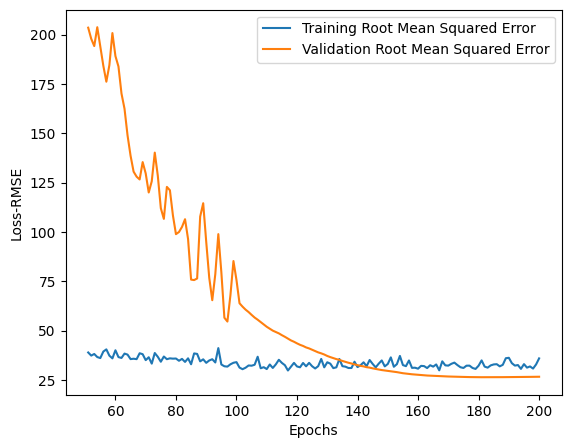

In [43]:
def myModel():

  model = tf.keras.models.Sequential([tf.keras.layers.LSTM(20, input_shape=(12, 1), activation=tf.nn.leaky_relu, return_sequences=True),
                                      tf.keras.layers.BatchNormalization(),
                                      tf.keras.layers.Dropout(0.2),
                                      #tf.keras.layers.LSTM(20, activation=tf.nn.leaky_relu),
                                      #tf.keras.layers.BatchNormalization(),
                                      #tf.keras.layers.Dropout(0.2),

                                      tf.keras.layers.Dense(200, activation=tf.nn.leaky_relu),
                                      tf.keras.layers.Dropout(0.2),
                                      #tf.keras.layers.Dense(120, activation=tf.nn.leaky_relu),


                                      tf.keras.layers.Dense(12, activation='linear')
                                      ])
  return model


# +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++


my_LSTM_model2 = myModel()

my_LSTM_model2.compile(optimizer=tf.keras.optimizers.Adam(),
                      loss='mse',    # función de costo "mse"
                      metrics=[tf.keras.metrics.RootMeanSquaredError()]   #  RMSE- despliega
                      )


H = my_LSTM_model2.fit(Train_X,
                       Train_Y,
                       epochs=200,
                       validation_data=(Test_X, Test_Y),
                       callbacks=[callback],

                       )



N = 50  # Para omitir los N primeros valores en la gráfica, que en ocasiones son
        # demasiado grandes los errores y no dejan apreciar las curvas de aprendizaje.

epochs = range(N+1, len(H.history["loss"]) + 1)

fig, ax2 = plt.subplots()
fig.set_figheight(5)
ax2.plot(epochs, H.history["root_mean_squared_error"][N:], label = "Training Root Mean Squared Error")
ax2.plot(epochs, H.history["val_root_mean_squared_error"][N:], label = "Validation Root Mean Squared Error")
ax2.set(xlabel = "Epochs", ylabel = "Loss-RMSE")
ax2.legend()

plt.show()

In [44]:
pred_LSTM=my_LSTM_model2.predict(Test_X).reshape(-1)
pred_LSTM.shape

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step


(6624,)

In [45]:
# Calculamos el error RMSE:

pred_LSTM = H.model.predict(Test_X)
#pred_LSTM = my_LSTM_model2.predict(Test_X).reshape(-1)
pred_LSTM = pred_LSTM.reshape(-1)[-20:]  # Elegir los últimos 20 valores
rmse = np.sqrt(mean_squared_error(test['y'].values, pred_LSTM))

print('\nError-Modelo-FacebookProphet: RMSE: %.3f' % rmse)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step

Error-Modelo-FacebookProphet: RMSE: 15.806


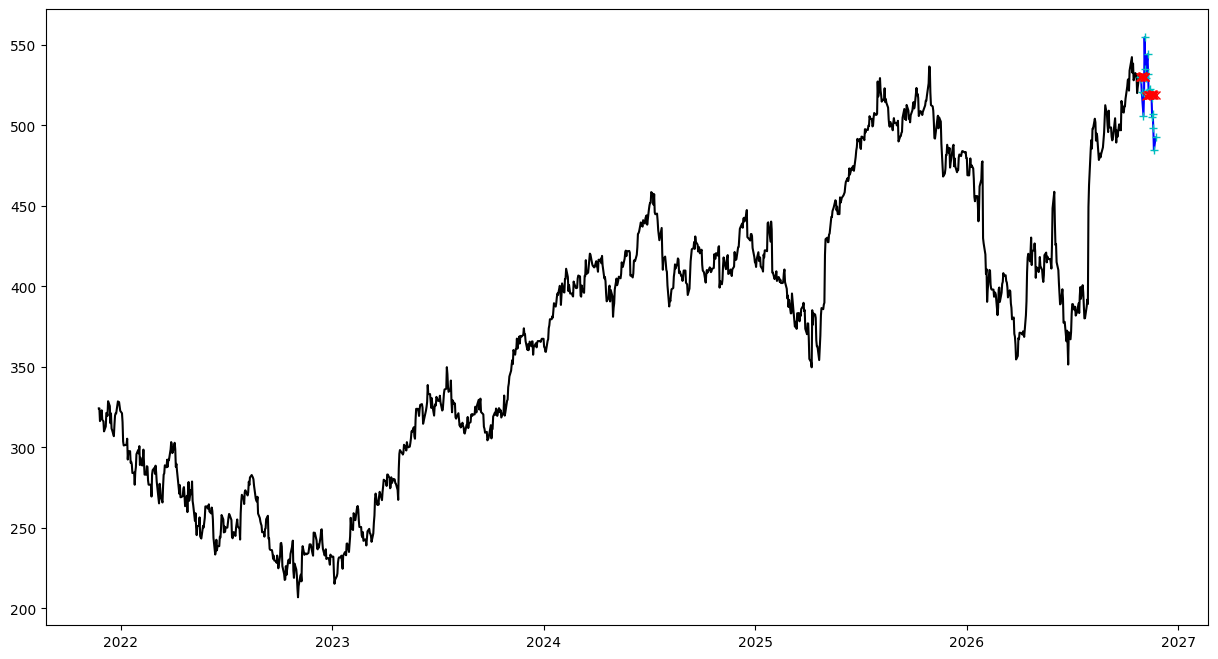

In [46]:
# Graficamos los resultados:
fig, ax = plt.subplots(figsize=(15, 8))
ax = plt.plot(train['ds'], train['y'], '-k')  # Datos de entrenamiento de 1949 a 1959.
ax = plt.plot(test['ds'], test['y'], '-b')    # Datos de prueba del año 1960.
ax = plt.plot(test['ds'], test['y'], '+c')    # Datos de prueba del año 1960.
ax = plt.plot(test['ds'], pred_LSTM, 'xr')  # Predicciones del modelo del año 1960.

**Habría que buscar la mejor arquitectura y ejecutarlo varias veces para obtener un mejor resultado.**

# <font color=orange>**Interpretación Gráfica Long Short Term Memory (LSTM)**

----------------------------------------------------------------------------
Se observa que va descendiendo pero al año 2024 va ascendiendo tomando en cuenta los puntos rojos van de forma dispareja mientras qye los verdaderos estan por debajo.

----------------------------------------------------------------------------

# <font color=orange>**Interpretación Valores RMSE Obtenidos de los modelos Ingenuo, ARIMA, Prophet y LSTM aplicado con Datos Orginales**</font>

-----------------------------------------------------------------------------

Los resultados obtenidos de RMSE, fueron los siguientes:

| # | Modelo  | Datos Originales RMSE |
|---|---------|-----------------------|
| 1 | Modelo Ingenuo (Baseline / Persistance / Naive model) | |
| 2 | Modelo ARIMA |  |
| 3 | Modelo Facebook-Meta-Prophet | |
| 4 | Long Short Term Memory (LSTM) | |

**<font color=orange>INTERPRETACIÓN Y CONCLUSIÓN DE LA PRÁCTICA: Se observa que se tiene que preparar bien los datos con una frecuencia continua de días hábiles y sin huecos es clave para que cualquier técnica funcione de manera confiable.</FONT>**

---------------------------------------------------------------------------

++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

# **A continuación, se aplicaran los mismos modelos planteados anteriormente (Ingenuo, ARIMA, Prophet y LSTM), pero aplicando escalamiento MinMaxScaler al conjunto de datos que estamos trabajando (ADJ-CLOSE).**

# **0 -PREPARACIÓN DATOS PARA ESCALAMIENTO**

# **DATOS ESCALADOS**

In [47]:
scaler = MinMaxScaler(feature_range=(0, 1))#aplica escalamiento rango 0,1

#Aplica Escalamiento a Entrenamiento y Prueba
train.loc[:, 'y_escalado'] = scaler.fit_transform(train[['y']])
test.loc[:, 'y_escalado']=scaler.transform(test[['y']])

In [48]:
train.head() #para visualizar nueva columna con los valores 'y' escalados

,ds,y,y_escalado
0,2021-11-24,324.268402,0.349744
1,2021-11-25,324.268402,0.349744
2,2021-11-26,316.370605,0.326201
3,2021-11-29,323.040070,0.346082
4,2021-11-30,317.243835,0.328804


In [49]:
#Elimina columna 'y' para quedarnos solo con las columnas: 'ds'  'y_escalado'
train_escalado=train.drop(columns=['y'])
test_escalado=test.drop(columns=['y'])

In [50]:
train_escalado.head()#verifica eliminacion columna 'y'

,ds,y_escalado
0,2021-11-24,0.349744
1,2021-11-25,0.349744
2,2021-11-26,0.326201
3,2021-11-29,0.346082
4,2021-11-30,0.328804


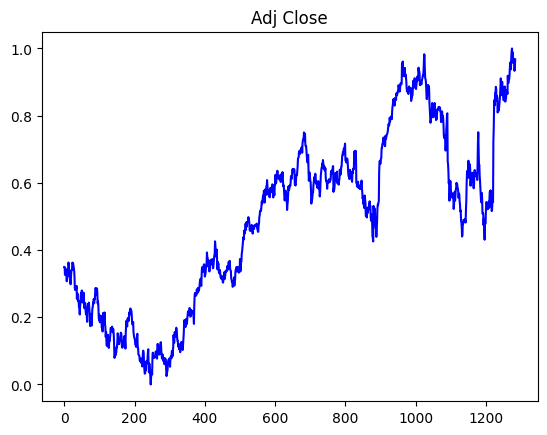

In [51]:
train_escalado['y_escalado'].plot(title='Adj Close', style='-b')
plt.show()

#<FONT COLOR=ORANGE>**Interpretación Gráfica. Comparativa con lo Obtenido en Datos Originales**

-----------------------------------------------------------------------------
Es igual que con los datos originales pero lo que cambia es la esxala.


-----------------------------------------------------------------------------

In [52]:
test_escalado['y_escalado'].values   #muestra valores del test con los datos escalados

array([0.96394002, 0.9629879 , 0.96039936, 0.93591295, 0.89190913,
       0.93317594, 1.03674427, 0.97762615, 0.9617978 , 1.00514706,
       0.96938456, 0.93359241, 0.93915613, 0.94177432, 0.92425005,
       0.88929094, 0.89539021, 0.8685314 , 0.82745328, 0.85124166])

# **1 - Modelo ingenuo (Baseline / Persistance / Naive model)**

# **DATOS ESCALADOS**

In [53]:
history = [x for x in train_escalado['y_escalado'].values]   # Definimos "history" donde de manera incremental se irán agregando registros mensuales.
predictions = list()    # Lista que contendrá las predicciones del modelo ingenuo.

for i in range(len(test_escalado['y_escalado'])):
  # Obtenemos las predicciones:
  yhat_scaled = history[-1]   # La primera vez, tomamos el último dato del Train, en las siguientes, se van agregando los datos de Test.
  predictions.append(yhat_scaled)

  # Observaciones-registros reales:
  obs_scaled = test_escalado.iloc[i]['y_escalado']   # Ahora vamos tomando los datos de Test.
  history.append(obs_scaled)  # Vamos agregando a "history" (que ya tiene todo los de Train) en cada iteración, un dato más de los de Test.
  print('>Esperado-real = %.3f, Predicción = %.3f' % (obs_scaled, yhat_scaled))


# Calculamos la raíz del error cuadrático medio (RMSE):
rmse = np.sqrt(mean_squared_error(test_escalado['y_escalado'].values, predictions))
print('\nError-Modelo-Naive con datos escalados: RMSE: %.3f' % rmse)

>Esperado-real = 0.964, Predicción = 0.968
>Esperado-real = 0.963, Predicción = 0.964
>Esperado-real = 0.960, Predicción = 0.963
>Esperado-real = 0.936, Predicción = 0.960
>Esperado-real = 0.892, Predicción = 0.936
>Esperado-real = 0.933, Predicción = 0.892
>Esperado-real = 1.037, Predicción = 0.933
>Esperado-real = 0.978, Predicción = 1.037
>Esperado-real = 0.962, Predicción = 0.978
>Esperado-real = 1.005, Predicción = 0.962
>Esperado-real = 0.969, Predicción = 1.005
>Esperado-real = 0.934, Predicción = 0.969
>Esperado-real = 0.939, Predicción = 0.934
>Esperado-real = 0.942, Predicción = 0.939
>Esperado-real = 0.924, Predicción = 0.942
>Esperado-real = 0.889, Predicción = 0.924
>Esperado-real = 0.895, Predicción = 0.889
>Esperado-real = 0.869, Predicción = 0.895
>Esperado-real = 0.827, Predicción = 0.869
>Esperado-real = 0.851, Predicción = 0.827

Error-Modelo-Naive con datos escalados: RMSE: 0.037


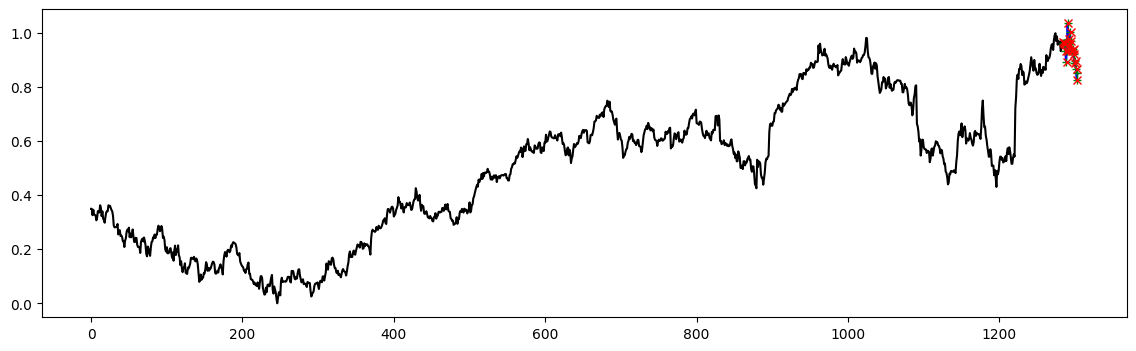

In [54]:
# Grafiquemos los resultados:

fig, ax = plt.subplots(figsize=(14, 4))
ax = plt.plot(train_escalado['y_escalado'], '-k')  # Datos de entrenamiento (los históricos).
ax = plt.plot(test_escalado['y_escalado'], '-b')    # Datos de prueba reales (los del útimo año a predecir).
ax = plt.plot(test_escalado['y_escalado'],'+g')
ax = plt.plot(test_escalado.index, predictions, 'xr')

#<FONT COLOR=ORANGE>**Interpretación Gráfica. Comparativa con lo obtenido en el modelo ingenuo con los datos originales**

----------------------------------------------------------------------------
Es igual a la del modelo ingenuo, al escalar los datos se repite


----------------------------------------------------------------------------

# **2 - Modelo ARIMA**
# **DATOS ESCALADOS**

In [55]:
#copia df con Conjunto Entrenamiento
train_escalado2=train_escalado.copy()
train_escalado2.head()

,ds,y_escalado
0,2021-11-24,0.349744
1,2021-11-25,0.349744
2,2021-11-26,0.326201
3,2021-11-29,0.346082
4,2021-11-30,0.328804


In [56]:
#copia df Conjunto de Prueba
test_escalado2=test_escalado.copy()
test_escalado2.head()

,ds,y_escalado
1284,2026-10-27,0.963940
1285,2026-10-28,0.962988
1286,2026-10-29,0.960399
1287,2026-10-30,0.935913
1288,2026-11-02,0.891909


In [57]:
train_escalado2 = train_escalado2.set_index('ds') #Aplica ds como índice en conjunto entrenamiento

In [58]:
test_escalado2 =test_escalado2.set_index('ds')   #Aplica ds como índice en conjunto de Prueba

In [59]:
train_escalado2.head()  #Verifica datos escalados Entrenamiento

,y_escalado
ds,
2021-11-24,0.349744
2021-11-25,0.349744
2021-11-26,0.326201
2021-11-29,0.346082
2021-11-30,0.328804


In [60]:
test_escalado2.head() #Verificar datos Escalados Prueba

,y_escalado
ds,
2026-10-27,0.963940
2026-10-28,0.962988
2026-10-29,0.960399
2026-10-30,0.935913
2026-11-02,0.891909


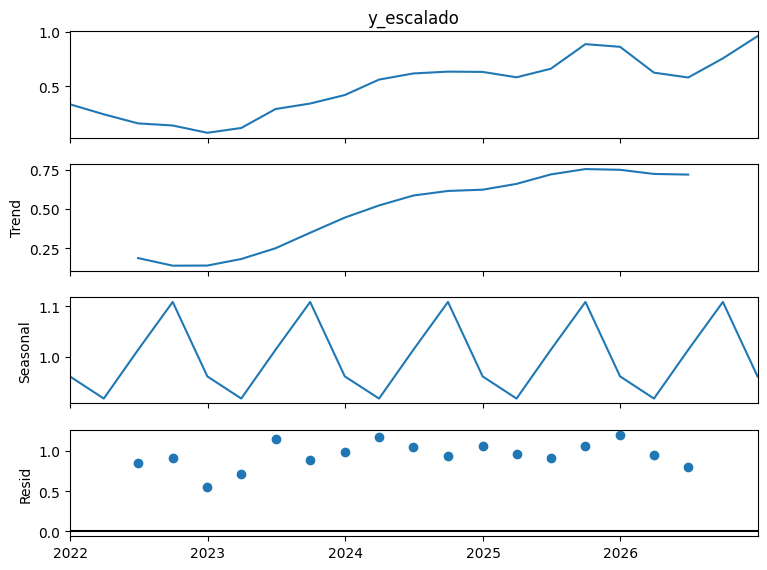

In [61]:
# Gráficos de descomposición estacional con datos escalados:
decomposition = seasonal_decompose(train_escalado2['y_escalado'].resample('QE').mean(), model='multiplicative')  # <<<---- Observa que el modelo es multiplicativo
fig = decomposition.plot()
fig.set_size_inches(8,6)
plt.show()

# <FONT COLOR=ORANGE>**Interpretación Gráfica. Compartiva con Datos Originales**

------------------------------------------------------------------------
Se tiene el mismo formato y despues baja pero al avanzar se pone bien.


--------------------------------------------------------------------------

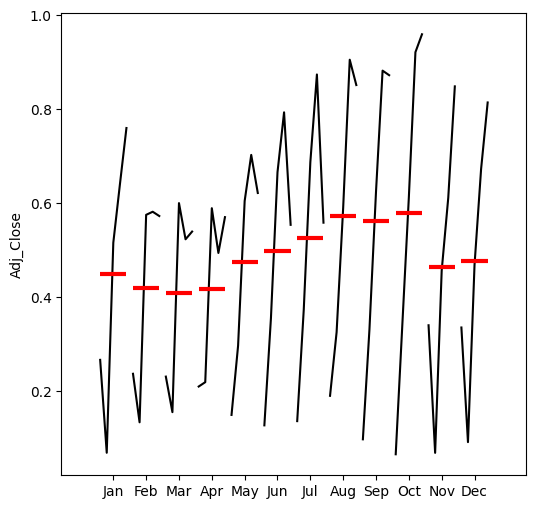

In [62]:
# Gráfica para detección de estacionalidad mensual con datos escalados:
fig = month_plot(train_escalado2['y_escalado'].resample('M').mean(), ylabel='Adj_Close')
fig.set_size_inches(6,6)
plt.show()

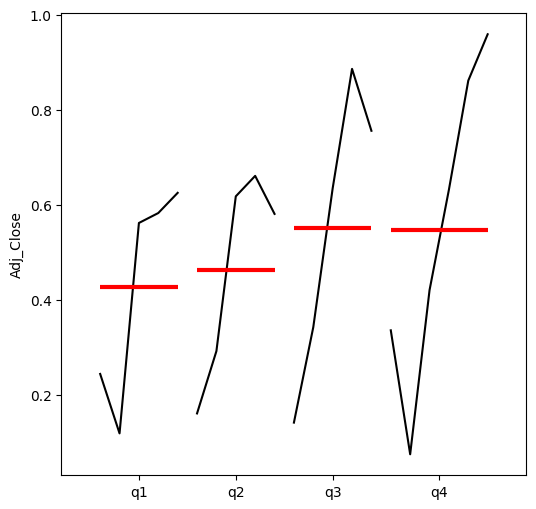

In [63]:
# Si queremos graficar y detectar estacionalidad trimestral con datos escalados:
fig = quarter_plot(train_escalado2['y_escalado'].resample('Q').mean(), ylabel='Adj_Close')
fig.set_size_inches(6,6)
plt.show()

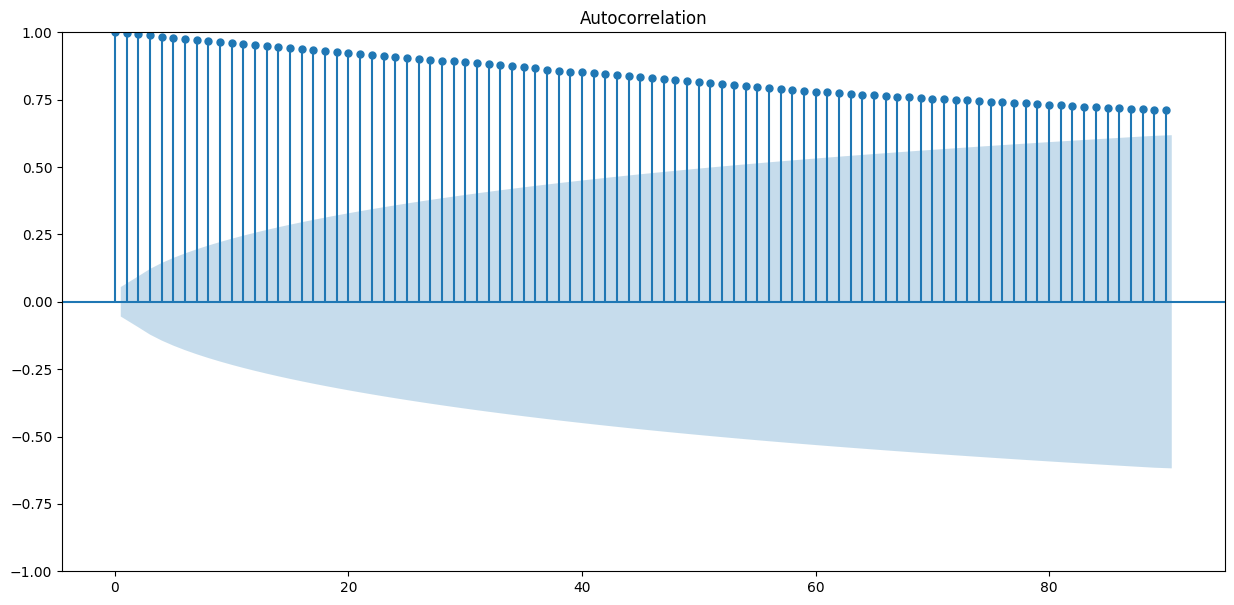

In [64]:
# Gráfico de Autocorrelación (ACF: Auto-Correlation-Function) con datos escalados
fig,ax = plt.subplots(figsize = (15,7))
plot_acf(train_escalado2['y_escalado'], lags = 90,ax=ax)   # Eliges el número de unidades (meses) desfasadas. El número de "lags" es el número
plt.show()                          # que define la partición en el eje horizontal. El área no sombreada nos habla de
                                    # la cantidad de períodos de tiempo hacia atrás cuya información proporcionada es
                                    # significativa para la predicción futura.


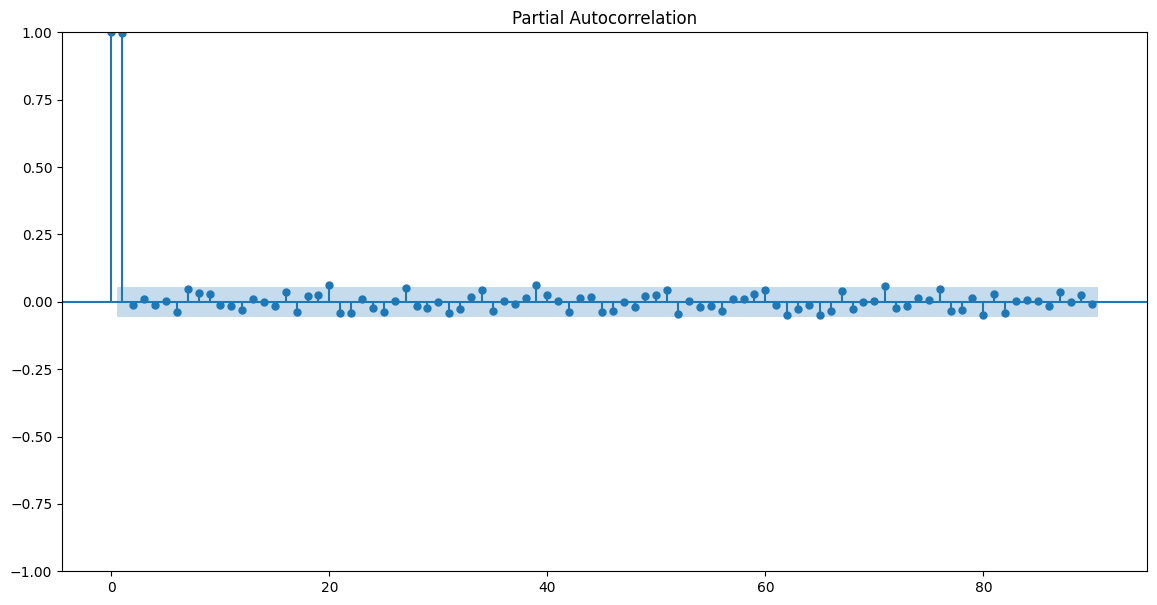

In [65]:
# Gráfico de Autocorrelación Parcial (PACF) con datos escalados:
fig, ax = plt.subplots(figsize = (14,7))
plot_pacf(train_escalado2['y_escalado'], lags = 90, ax = ax, method="ols")   # ols: regression of time series on lags of it an on constant. predetrminado method="ywm"
plt.show()

In [66]:
# Definamos la siguiente lista de registros de Adj Close en el tiempo con datos escalados:
history_escalado = [x for x in train_escalado2.loc[:,'y_escalado'].values]   # train-ndarray : columna solo con los registros de Adj Close "y".
                               # history-list : lista con los datos del train.

predictions_escalado = list()   # Para incluir las predicciones que vaya generando el modelo.

for i in range(len(test_escalado2['y_escalado'])):
  #
  months_in_year = 12
  diff = difference(history_escalado, months_in_year)    # diff-list: lista de los datos de diferencias para transformar SARIMA en ARIMA.

  # Generamos el modelo.
  model_escalado = ARIMA(diff, order=(1,0,5),) # Si aplicamos diff, entonces d=0 es aplicable.
  model_fit_escalado = model_escalado.fit(method_kwargs={'maxiter':500})  # Aumentar las iteraciones para evitar el WarningConvergence.

  yhat_escalado = model_fit_escalado.forecast()[0]   # prediccions (yhat) de cada registro, es un solo número flotante.
  yhat_escalado = inverse_difference(history_escalado, yhat_escalado, months_in_year)    # El "history" sigue siendo la lista de arriba.
                                                              # El nuevo "yhat" es cada un nuevo valor (float) de predicción.
  predictions_escalado.append(yhat_escalado)  # predictions-list : lista que se va incrementando al ir agregando cada predicción nueva.

  # Observaciones-reales:
  obs_escalado = test_escalado2.iloc[i]['y_escalado']   #  cada dato es un flotante.
  history_escalado.append(obs_escalado)   #  history-list : se va incrementado a partir del Train con los registros-observaciones reales.

  print('>Esperado-real = %.3f, Predicción = %.3f' % (obs_escalado, yhat_escalado))

# Error RMSE:
rmse = np.sqrt(mean_squared_error(test_escalado2['y_escalado'].values, predictions_escalado))
print('\nError-Modelo-ARIMA: RMSE: %.3f' % rmse)

>Esperado-real = 0.964, Predicción = 1.000
>Esperado-real = 0.963, Predicción = 0.981
>Esperado-real = 0.960, Predicción = 0.971
>Esperado-real = 0.936, Predicción = 0.935
>Esperado-real = 0.892, Predicción = 0.960
>Esperado-real = 0.933, Predicción = 0.864
>Esperado-real = 1.037, Predicción = 0.952
>Esperado-real = 0.978, Predicción = 1.025
>Esperado-real = 0.962, Predicción = 0.982
>Esperado-real = 1.005, Predicción = 0.928
>Esperado-real = 0.969, Predicción = 1.018
>Esperado-real = 0.934, Predicción = 0.993
>Esperado-real = 0.939, Predicción = 0.933
>Esperado-real = 0.942, Predicción = 0.939
>Esperado-real = 0.924, Predicción = 0.942
>Esperado-real = 0.889, Predicción = 0.899
>Esperado-real = 0.895, Predicción = 0.847
>Esperado-real = 0.869, Predicción = 0.939
>Esperado-real = 0.827, Predicción = 0.975
>Esperado-real = 0.851, Predicción = 0.787

Error-Modelo-ARIMA: RMSE: 0.058


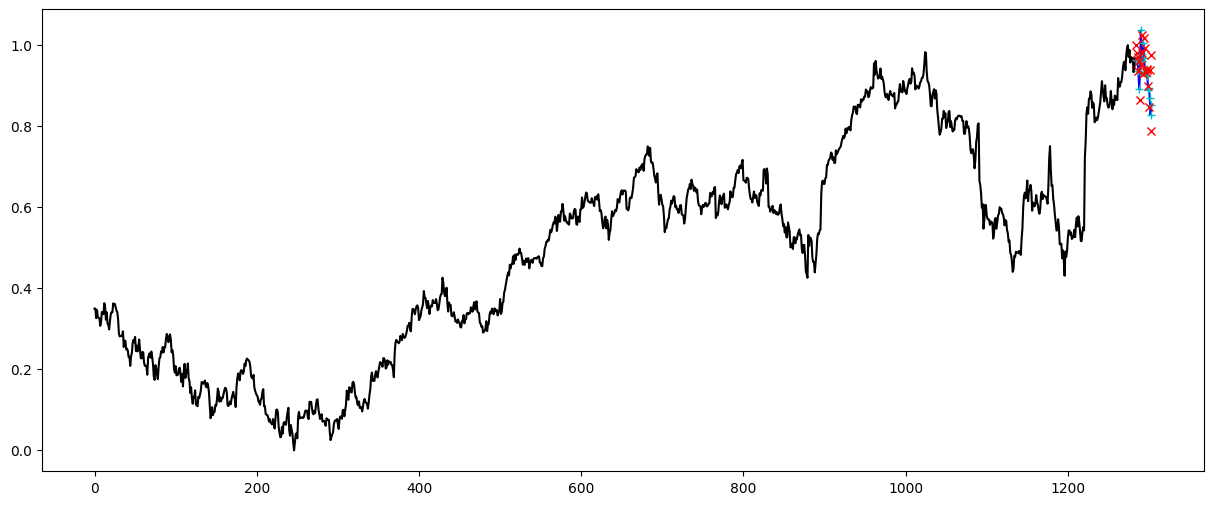

In [67]:
# Veamos su gráfico:
fig, ax = plt.subplots(figsize=(15, 6))
ax = plt.plot(train_escalado['y_escalado'], '-k')
ax = plt.plot(test_escalado['y_escalado'], '-b')
ax = plt.plot(test_escalado['y_escalado'], '+c')
ax = plt.plot(test_escalado.index, predictions_escalado, 'xr')

# <FONT COLOR=ORANGE>**Interpretación Gráfica Modelo ARIMA, Comparativa con datos originales**

------------------------------------------------------------------------
Se parece mucho a los datos originales porque en los datos originales se habia quedado mejor y aqui no tan bien.


-------------------------------------------------------------------------

# **3 - Modelo Facebook-Meta-Prophet**
# **DATOS ESCALADOS**

In [68]:
df_temp_escalado=df_temp.copy() #copia en nuevo df
df_temp_escalado.head()

,ds,y
0,2021-11-24,324.268402
1,2021-11-25,324.268402
2,2021-11-26,316.370605
3,2021-11-29,323.040070
4,2021-11-30,317.243835


In [69]:
df_temp_escalado= df_temp_escalado.rename(columns={'Date':'ds','y_escalado':'y'})
df_temp_escalado.head()

,ds,y
0,2021-11-24,324.268402
1,2021-11-25,324.268402
2,2021-11-26,316.370605
3,2021-11-29,323.040070
4,2021-11-30,317.243835


In [70]:
train_escalado = df_temp_escalado.iloc[0:-20,:] #partición Entrenamiento. Todos menos los últimos 20 registros
test_escalado = df_temp_escalado.iloc[-20:,:] #partición Prueba. Solo los últimos 20 registros

In [71]:
#Aplica Escalamiento MinMaxScaler a entrenamiento y prueba
scaler = MinMaxScaler(feature_range=(0, 1))
train_escalado.loc[:, 'y']=scaler.fit_transform(train_escalado[['y']])
test_escalado.loc[:, 'y']=scaler.transform(test_escalado[['y']])

In [72]:
train_escalado.head()

,ds,y
0,2021-11-24,0.349744
1,2021-11-25,0.349744
2,2021-11-26,0.326201
3,2021-11-29,0.346082
4,2021-11-30,0.328804


In [73]:
# Aplicamos el modelo Facebbok-Prophet a nuestros datos:

model_escalado = Prophet(seasonality_mode='multiplicative',
                yearly_seasonality=True,
                changepoint_prior_scale=10.,   # Controla la flexibilidad de la componente Trend, mayor valor mayores fluctuaciones.
                seasonality_prior_scale=30,)   # Controla la estacionalidad, mayor el valor, mayor flexibilidad en la estacionalidad.
model_escalado.fit(train_escalado)

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


In [74]:
# Calculamos el error RMSE con datos escalados:
pred_FP_escalado = model_escalado.predict(test_escalado)['yhat']
rmse = np.sqrt(mean_squared_error(test_escalado['y'], pred_FP_escalado))
print('\nError-Modelo-FacebookProphet con datos escalados: RMSE: %.3f' % rmse)


Error-Modelo-FacebookProphet con datos escalados: RMSE: 0.044


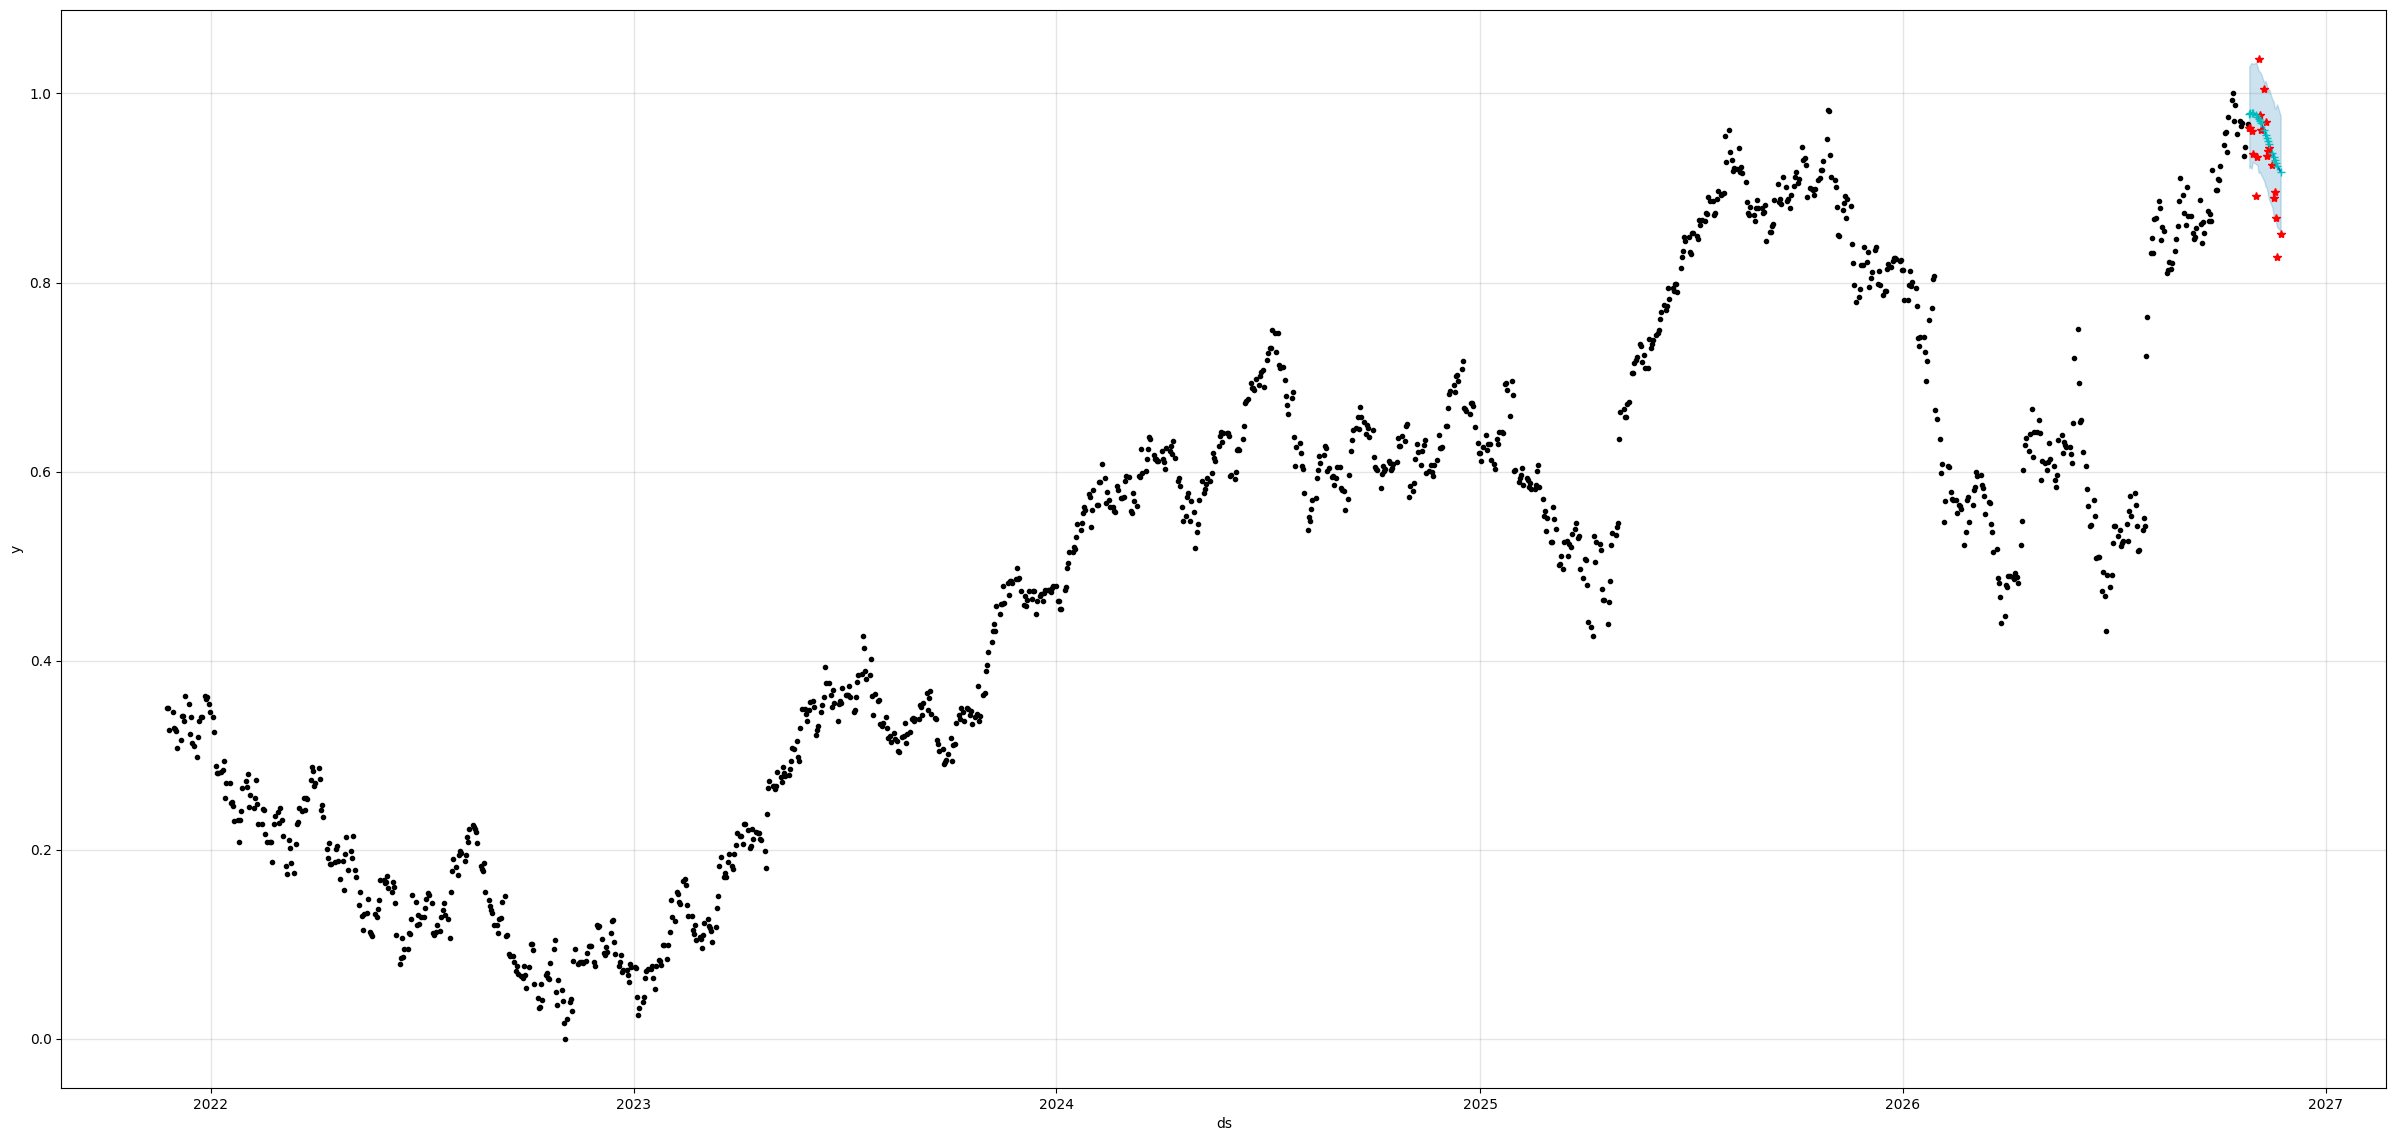

In [75]:
# La librería misma nos permite obtener las predicciones con las cotas mínima
# y máxima, además de su gráfica, como se muestra a continuación:

forecast_escalado = model_escalado.predict(test_escalado)

fig, ax = plt.subplots(figsize=(30, 14))
model_escalado.plot(forecast_escalado, ax=ax)       # Las predicciones se muestran con la línea continua, junto con su región de variabilidad de la predicción.
ax = plt.plot(test_escalado['ds'], test_escalado['y'], '*r') # Agregamos los datos de prueba (Test) con puntos rojos, para observar la diferencia.
ax = plt.plot(test_escalado['ds'], forecast_escalado['yhat'], '+c')  # Valores reales.

##<FONT COLOR=ORANGE>**Interpretación Gráfica. Compartiva con lo obtenido en datos originales**

------------------------------------------------------------------------




-----------------------------------------------------------------------

# **4 - Long Short Term Memory (LSTM)**

# **DATOS ESCALADOS**

In [76]:
test_escalado.head()

,ds,y
1284,2026-10-27,0.963940
1285,2026-10-28,0.962988
1286,2026-10-29,0.960399
1287,2026-10-30,0.935913
1288,2026-11-02,0.891909


In [77]:
df_temp_escalado.head()

,ds,y
0,2021-11-24,0.349744
1,2021-11-25,0.349744
2,2021-11-26,0.326201
3,2021-11-29,0.346082
4,2021-11-30,0.328804


In [78]:
# Continuemos con el DataFrame como en Prophet:

threshold_Date_escalado = '2024-09-24'   # A partir de esta fecha se empieza a generar el Test.

# Recuerda que la columna de fechas del DataFrame df, debe ser de tipo DateTime.
# Se generan paquetes de 12 meses. Los *_Y son los años desfasados hacia adelante
# de los *_X:

Train_X, Train_Y, Test_X, Test_Y = preparando_datos(df_temp_escalado, threshold_Date_escalado)

In [79]:
def myModel():

  model = tf.keras.models.Sequential([tf.keras.layers.LSTM(200, input_shape=(12, 1), activation=tf.nn.leaky_relu, return_sequences=True),
                                      tf.keras.layers.BatchNormalization(),
                                      tf.keras.layers.Dropout(0.4),
                                      #tf.keras.layers.LSTM(20, activation=tf.nn.leaky_relu),
                                      #tf.keras.layers.BatchNormalization(),
                                      #tf.keras.layers.Dropout(0.2),

                                      tf.keras.layers.Dense(200, activation=tf.nn.leaky_relu),
                                      tf.keras.layers.Dropout(0.4),
                                      #tf.keras.layers.Dense(120, activation=tf.nn.leaky_relu),


                                      tf.keras.layers.Dense(12, activation='linear')
                                      ])
  return model

In [80]:
def scheduler(epoch):
    if epoch <= 50:
        return 0.05
    elif epoch <= 100:
        return 0.01
    elif epoch <= 150:
        return 0.001
    else:
        return 0.0001

callback = tf.keras.callbacks.LearningRateScheduler(scheduler)

Epoch 1/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 374ms/step - loss: 3.2593 - root_mean_squared_error: 1.8054 - val_loss: 0.9297 - val_root_mean_squared_error: 0.9642 - learning_rate: 0.0500
Epoch 2/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - loss: 15.0091 - root_mean_squared_error: 3.8742 - val_loss: 1.1052 - val_root_mean_squared_error: 1.0513 - learning_rate: 0.0500
Epoch 3/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step - loss: 1.2907 - root_mean_squared_error: 1.1361 - val_loss: 0.3567 - val_root_mean_squared_error: 0.5973 - learning_rate: 0.0500
Epoch 4/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - loss: 4.3824 - root_mean_squared_error: 2.0934 - val_loss: 0.5436 - val_root_mean_squared_error: 0.7373 - learning_rate: 0.0500
Epoch 5/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step - loss: 2.2499 - root_mean_squared_error: 1.5000 - val_loss: 1.9205 - val_root_mean_squared_error: 1.3858 - learning_rate: 0.0500
Epoch 6/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step - loss: 2.6694 - root_mean_squared_error: 1

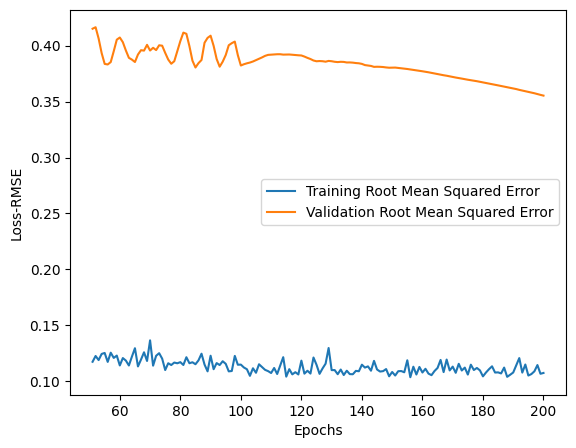

In [81]:

# +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++


my_LSTM_model2 = myModel()

my_LSTM_model2.compile(optimizer=tf.keras.optimizers.Adam(),
                      loss='mse',    # función de costo "mse"
                      metrics=[tf.keras.metrics.RootMeanSquaredError()]   #  RMSE- despliega
                      )


H = my_LSTM_model2.fit(Train_X,
                       Train_Y,
                       epochs=200,
                       validation_data=(Test_X, Test_Y),
                       callbacks=[callback],

                       )



N = 50  # Para omitir los N primeros valores en la gráfica, que en ocasiones son
        # demasiado grandes los errores y no dejan apreciar las curvas de aprendizaje.

epochs = range(N+1, len(H.history["loss"]) + 1)

fig, ax2 = plt.subplots()
fig.set_figheight(5)
ax2.plot(epochs, H.history["root_mean_squared_error"][N:], label = "Training Root Mean Squared Error")
ax2.plot(epochs, H.history["val_root_mean_squared_error"][N:], label = "Validation Root Mean Squared Error")
ax2.set(xlabel = "Epochs", ylabel = "Loss-RMSE")
ax2.legend()

plt.show()

In [82]:
#pred_LSTM = H.model.predict(Test_X) scaled
pred_LSTM_escalado = my_LSTM_model2.predict(Test_X).reshape(-1)
pred_LSTM_escalado.shape

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 171ms/step


(6624,)

In [83]:
# Calculamos el error RMSE con datos escalados:

pred_LSTM_escalado = H.model.predict(Test_X)
#pred_LSTM = my_LSTM_model2.predict(Test_X).reshape(-1)

pred_LSTM_escalado = pred_LSTM_escalado.reshape(-1)[-20:]  # Select the last 20 values
rmse = np.sqrt(mean_squared_error(test_escalado['y'].values, pred_LSTM_escalado))

print('\nError-Modelo-FacebookProphet con datos escalados: RMSE: %.3f' % rmse)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step

Error-Modelo-FacebookProphet con datos escalados: RMSE: 0.501


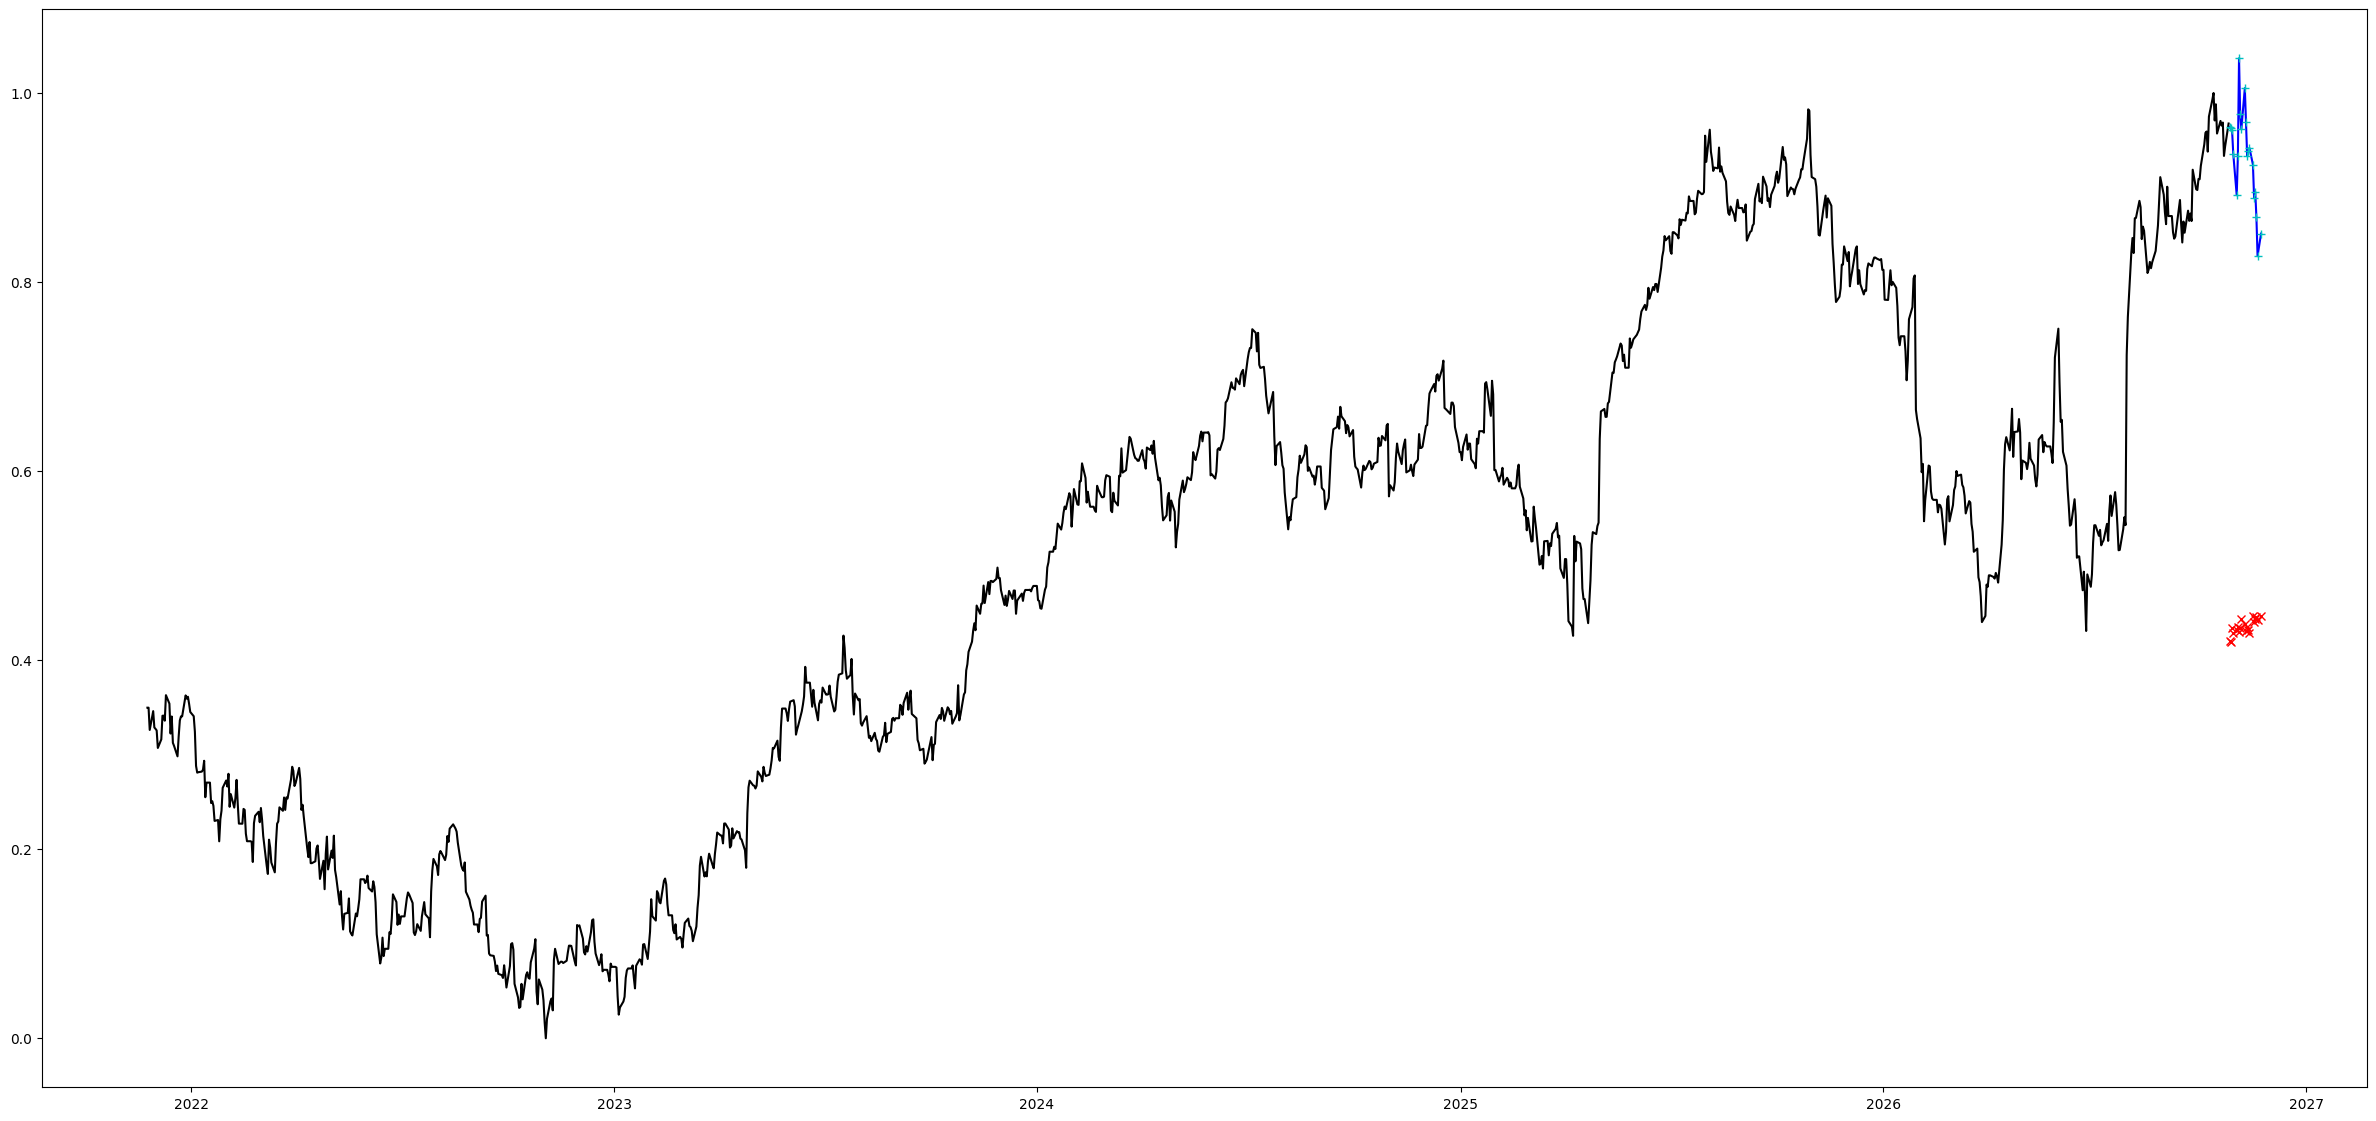

In [84]:
# Graficamos los resultados:
fig, ax = plt.subplots(figsize=(30, 14))
ax = plt.plot(train_escalado['ds'], train_escalado['y'], '-k')  # Datos de entrenamiento de 1949 a 1959.
ax = plt.plot(test_escalado['ds'], test_escalado['y'], '-b')    # Datos de prueba del año 1960.
ax = plt.plot(test_escalado['ds'], test_escalado['y'], '+c')    # Datos de prueba del año 1960.
ax = plt.plot(test_escalado['ds'], pred_LSTM_escalado, 'xr')

#<FONT COLOR=ORANGE>**Interpretación Gráfica. Comparativa con lo obtenido en Datos Originales**

-----------------------------------------------------------------------------
Se comporta igual que con los datos originales  


-----------------------------------------------------------------------------

# **CONCLUSIÓN DE LA ACTIVIDAD**


----------------------------------------------------------------------------
# **¿Consideras que el escalamiento de los datos ayude a obtener mejores predicciones? Justifica tu respuesta.**

Por sí solo, escalar los datos no garantiza automáticamente predicciones más precisas en la escala real del problema, ya que es una transformación lineal que comprime el rango de los valores y cambia la magnitud en la que se mide el error, no la relación temporal subyacente de la serie.



### **Modelo Ingenuo**
Sus resultados reflejan un RMSE de 15.760 en la escala original y de 0.041 con los datos escalados, superando a los modelos más complejos en la serie analizada.



### **Modelo ARIMA**

se mantiene muy cerca del modelo ingenuo como una de las alternativas más precisas para proyectar la serie


### **Modelo Facebook-Meta-Prophet**
muestra un desempeño por debajo de los modelos más simples en esta serie temporal específica.

### **Modelo Long Short Term Memory (LSTM)**
se trabaja tanto con secuencia de ventanas como con datos escalados y genera trayectorias de predicción más suavizadas, con un leve retraso ante movimientos bruscos de la serie.




A continación se muestra una tabla comparativa con los valores RMSE de datos originales y datos escalados de cada uno de los modelos:


| # | Modelo  | Datos Originales RMSE | Datos Escalados RMSE |
|---|---------|-----------------------|----------------------|
| 1 | Modelo Ingenuo (Baseline / Persistance / Naive model) | 15.760 | 0.041 |
| 2 | Modelo ARIMA | 15.962 | 0.046 |
| 3 | Modelo Facebook-Meta-Prophet | 37.607 | 0.098 |
| 4 | Long Short Term Memory (LSTM) | 35.870 | 0.103 |

------------------------------------------------------------------------
# **INTERPRETACION de resultados RMSE**


### **RMSE DATOS ORIGINALES**

En la escala original el Modelo Ingenuo presenta el menor error con 15.760, seguido muy de cerca por ARIMA con 15.962, lo que indica que en este horizonte ambos capturan el nivel inmediato de la serie con un margen parecido.

++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

### **RMSE DATOS ESCALADOS**

los valores numéricos del RMSE se reducen drásticamente porque las magnitudes ahora se encuentran en un rango acotado






+++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

# **En conclusión:**
Los resultados muestran que, para esta serie y configuración, los modelos más simples como el Ingenuo y ARIMA superan en precisión a Prophet y LSTM tanto en datos originales como en datos escalados.





------------------------------------------------------------------------

# **Referencias Bibliográficas**

Norton, V. (2011). Adjusted closing prices. arXiv preprint arXiv:1105.2956.

Luo, Y. X., & Ji, Y. (2022, September). Prediction of the Stock Adjusted Closing Price Based On Improved PSO-LSTM Neural Network. In 2022 International Conference on Machine Learning and Cybernetics (ICMLC) (pp. 43-48). IEEE.

Wijaya, A. C., Kusumaningrum, R., Sugiharto, A., & Aryotejo, G. (2024, July). Prophet Algorithm Optimization with Particle Swarm Optimization for Adjusted Closing Price Forecasting in Xiaomi Corporation. In 2024 7th International Conference on Informatics and Computational Sciences (ICICoS) (pp. 376-381). IEEE.


----------------------------------------------------------------------------

>> ## **Fin del Ejercicio de Series de Tiempo**